# TEXTSENSE — ĐỒ ÁN KHOA HỌC DỮ LIỆU

**Notebook thực hành theo 4 câu của đề.** Mỗi bước có một cell nhỏ, kết quả bảng và biểu đồ hiện ngay bên dưới khi chạy. Chạy lần lượt từ trên xuống. Dữ liệu sử dụng: **Twitter (`Twitter_Data.csv`) và Reddit (`Reddit_Data.csv`)** từ bộ dữ liệu Kaggle *Twitter and Reddit Sentimental Analysis Dataset* (`cosmos98`).

**Bản chất nhãn gốc:** Nhãn `-1 / 0 / 1` trên Kaggle được gán tự động bằng công cụ phân tích cảm xúc (lexicon/rule-based), không phải nhãn gán tay bởi con người. Do đó, nhãn của mô hình là **"tiêu cực theo nhãn gốc" (proxy label)**, không phải sự thật tuyệt đối hay nhãn xác minh hành vi phân biệt đối xử.

**Quyết định bài toán 2 lớp:** Ánh xạ `-1 → 1 (Tiêu cực)` và `0, +1 → 0 (Không tiêu cực)` để đáp ứng đúng yêu cầu phân loại nhị phân. Phần mở rộng 3 lớp (`-1 / 0 / 1`) được thực nghiệm thêm ở Câu 3 để chứng minh việc gộp Trung tính (`0`) với Tích cực (`1`) là có chủ đích.

**SQL Server:** Notebook tự kết nối tới `TextSenseDB` bằng Windows Authentication trên `localhost` (ưu tiên ODBC 18, tự dùng ODBC 17 nếu máy chỉ có Driver 17). Có thể ghi đè bằng biến môi trường `TEXTSENSE_SQLSERVER_CONNECTION_STRING` (hoặc đặt `TEXTSENSE_SKIP_SQL=1` nếu chạy kiểm thử ngoại tuyến không có SQL Server).

## CÂU 1 — THU THẬP, PHÂN TÍCH VÀ THỐNG KÊ MÔ TẢ (2,0 ĐIỂM)

**1.1. Khai báo thư viện**

In [1]:
# Nhập các thư viện cần dùng; không tự chạy quá trình train.
import argparse
import hashlib
import json
import os
import platform
import re
import unicodedata
import tempfile
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path
from typing import Iterable

import joblib
from joblib import Memory
import numpy as np
import pandas as pd
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_recall_fscore_support)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

**1.2. Khai báo dữ liệu và quy ước nhãn**

In [2]:
# Xác định data, outputs và ánh xạ nhãn -1/0/1 sang 1/0.
ROOT = Path.cwd().resolve()
if not (ROOT / 'data' / 'Twitter_Data.csv').exists():
    ROOT = ROOT / '01_TRAIN_MODEL'
if not (ROOT / 'data' / 'Twitter_Data.csv').exists():
    raise FileNotFoundError('Mở notebook ở thư mục 01_TRAIN_MODEL hoặc TextSense (thư mục gốc).')
DATA = ROOT / 'data'
OUTPUT = ROOT / 'outputs'
SEED = 42
# These are proxy labels derived from sentiment, NOT ground-truth racism/sexism labels.
BINARY_MAPPING = {-1: 1, 0: 0, 1: 0}
BINARY_NAMES = {0: 'Không tiêu cực', 1: 'Tiêu cực'}
DEFAULT_C_VALUES = (0.5, 1.0, 2.0, 5.0)
DATASET_URL = 'https://www.kaggle.com/datasets/cosmos98/twitter-and-reddit-sentimental-analysis-dataset'
DATASET_LICENSE = 'CC BY-NC-SA 4.0 (as displayed on the Kaggle dataset page; verify terms before redistribution)'


RETWEET_PREFIX_RE = re.compile(r'^\s*rt\s+@[\w_]+\s*:?[ \t]*', flags=re.I)
URL_RE = re.compile(r'(?:https?://|www\.)\S+', flags=re.I)

In [3]:
# Chuẩn hóa text để thống kê, huấn luyện và dự đoán thống nhất (đồng bộ 100% với 03_GIAO_DIEN/predict.py).
PREPROCESSING_VERSION = 'textsense_clean_v3_context'
_CONTRACTIONS = {
    'aint': 'is not', 'cant': 'can not', 'cannot': 'can not',
    'wont': 'will not', 'shant': 'shall not',
}
for _stem, _base in (
    ('aren', 'are'), ('couldn', 'could'), ('didn', 'did'),
    ('doesn', 'does'), ('don', 'do'), ('hadn', 'had'),
    ('hasn', 'has'), ('haven', 'have'), ('isn', 'is'),
    ('mightn', 'might'), ('mustn', 'must'), ('needn', 'need'),
    ('shouldn', 'should'), ('wasn', 'was'), ('weren', 'were'),
    ('wouldn', 'would'),
):
    _CONTRACTIONS[_stem + 't'] = _base + ' not'
_CONTRACTIONS.update({
    (word[:-1] + "'t"): expanded for word, expanded in list(_CONTRACTIONS.items())
    if word.endswith('nt') and word not in {'cannot'}
})
_CONTRACTIONS_RE = re.compile(
    r'\b(?:' + '|'.join(re.escape(t) for t in sorted(_CONTRACTIONS, key=len, reverse=True)) + r')\b',
    flags=re.IGNORECASE,
)

def normalize_text(value) -> str:
    """NFKC, RT/URL, contractions, lowercase, tách dấu câu và khoảng trắng.

    Idempotent: normalize_text(normalize_text(x)) == normalize_text(x).
    PHẢI đồng bộ chính xác giữa notebook và 03_GIAO_DIEN/predict.py.
    """
    if value is None or pd.isna(value):
        return ''
    value = unicodedata.normalize('NFKC', str(value)).replace('’', "'")
    value = RETWEET_PREFIX_RE.sub(' ', value)
    value = URL_RE.sub(' ', value)
    value = value.casefold()
    value = _CONTRACTIONS_RE.sub(lambda m: _CONTRACTIONS[m.group(0)], value)
    value = re.sub(r'[^\w\s]', ' ', value, flags=re.UNICODE)
    value = value.replace('_', ' ')
    return ' '.join(value.split())

In [4]:
# Tạo khóa phát hiện văn bản trùng.
def token_key(value) -> str:
    """Canonical token key used for deduplication and split-leakage checks."""
    value = unicodedata.normalize('NFKC', normalize_text(value)).casefold()
    tokens = re.findall(r'\w+', value, flags=re.UNICODE)
    return ' '.join(tokens)


In [5]:
# Tính mã kiểm tra nguồn CSV.
def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(chunk_size), b''):
            digest.update(chunk)
    return digest.hexdigest()


In [6]:
# Tính mã kiểm tra dữ liệu sau xử lý.
def sha256_frame(frame: pd.DataFrame, columns: Iterable[str]) -> str:
    stable = frame[list(columns)].copy()
    sort_cols = [c for c in ('dedup_key', 'category', 'label', 'source', 'text') if c in stable]
    if sort_cols:
        stable = stable.sort_values(sort_cols, kind='mergesort').reset_index(drop=True)
    payload = stable.to_csv(index=False, lineterminator='\n').encode('utf-8')
    return hashlib.sha256(payload).hexdigest()


In [7]:
# Đọc cả Twitter_Data.csv và Reddit_Data.csv.
def read_sources(data_dir: Path = DATA) -> tuple[pd.DataFrame, dict]:
    data_dir = Path(data_dir)
    items, source_hashes = [], {}
    for filename, col in [('Twitter_Data.csv', 'clean_text'), ('Reddit_Data.csv', 'clean_comment')]:
        path = data_dir / filename
        if not path.is_file():
            raise FileNotFoundError(f'Missing data file: {path}. Copy both CSV files into the data folder.')
        source_hashes[filename] = sha256_file(path)
        frame = pd.read_csv(path, dtype={col: 'string'}, low_memory=False)
        missing = {col, 'category'} - set(frame.columns)
        if missing:
            raise ValueError(f'{filename} missing required columns: {sorted(missing)}')
        part = frame[[col, 'category']].rename(columns={col: 'text'}).copy()
        part['source'] = filename
        items.append(part)
    return pd.concat(items, ignore_index=True), source_hashes

In [8]:
# Loại dòng không hợp lệ / quá ngắn / rỗng / trùng và ghi nhận số dòng bị loại ở từng bước.
def clean_sentiment(data_dir: Path = DATA) -> tuple[pd.DataFrame, dict]:
    df, source_hashes = read_sources(data_dir)
    raw_category = pd.to_numeric(df['category'], errors='coerce')
    stats = {
        'raw_rows': int(len(df)),
        'raw_source_counts': {str(k): int(v) for k, v in df['source'].value_counts().items()},
        'raw_category_counts': {str(int(k)): int(v) for k, v in raw_category.value_counts().sort_index().items() if pd.notna(k)},
        'raw_source_category_counts': {
            str(source): {str(int(k)): int(v) for k, v in values.items() if pd.notna(k)}
            for source, group in df.assign(_category_num=raw_category).groupby('source')
            for values in [group['_category_num'].value_counts().sort_index()]
        },
        'source_file_sha256': source_hashes
    }
    before_na = len(df)
    df = df.dropna(subset=['text', 'category']).copy()
    stats['dropped_na_rows'] = int(before_na - len(df))

    stats['retweet_prefix_rows_normalized'] = int(df['text'].astype(str).str.match(RETWEET_PREFIX_RE).sum())
    df['text'] = df['text'].map(normalize_text)
    df['category'] = pd.to_numeric(df['category'], errors='coerce')

    invalid_cat_mask = ~df['category'].isin([-1, 0, 1])
    stats['invalid_category_rows'] = int(invalid_cat_mask.sum())
    df = df.loc[~invalid_cat_mask].copy()

    text_len = df['text'].str.len()
    stats['empty_after_normalize_rows'] = int((text_len == 0).sum())
    stats['too_short_rows_lt3'] = int(((text_len > 0) & (text_len < 3)).sum())
    df = df.loc[text_len >= 3].copy()
    df['category'] = df['category'].astype('int64')
    stats['valid_before_dedup'] = int(len(df))

    df['dedup_key'] = df['text'].map(token_key)
    empty_key_mask = df['dedup_key'].str.len() == 0
    stats['empty_token_key_rows'] = int(empty_key_mask.sum())
    df = df.loc[~empty_key_mask].copy()

    conflicts = df.groupby('dedup_key')['category'].nunique()
    conflicting_keys = set(conflicts[conflicts > 1].index)
    stats['conflicting_token_groups_removed'] = int(len(conflicting_keys))
    conflict_mask = df['dedup_key'].isin(conflicting_keys)
    stats['conflicting_token_rows_removed'] = int(conflict_mask.sum())
    df = df.loc[~conflict_mask].copy()

    before = len(df)
    df = df.drop_duplicates('dedup_key', keep='first').reset_index(drop=True)
    stats['duplicate_token_rows_removed'] = int(before - len(df))
    stats['unique_trainable_rows'] = int(len(df))
    stats['counts'] = {str(int(k)): int(v) for k, v in df['category'].value_counts().sort_index().items()}
    stats['source_counts'] = {str(k): int(v) for k, v in df['source'].value_counts().items()}
    stats['clean_source_category_counts'] = {
        str(source): {str(int(k)): int(v) for k, v in group['category'].value_counts().sort_index().items()}
        for source, group in df.groupby('source')
    }
    stats['canonical_dataset_sha256'] = sha256_frame(df, ['dedup_key', 'category', 'source'])
    return df, stats

**1.3. Đọc dữ liệu từ hai nguồn và xem 5 dòng đầu**

In [9]:
# Nạp cả hai CSV, làm sạch, thêm nhãn 0/1 và báo cáo số dòng bị loại ở từng bước.
from IPython.display import display
assert (DATA / 'Twitter_Data.csv').is_file() and (DATA / 'Reddit_Data.csv').is_file()
clean_df, source_stats = clean_sentiment(DATA)
clean_df['label'] = clean_df['category'].map(BINARY_MAPPING).astype(int)
assert {'Twitter_Data.csv', 'Reddit_Data.csv'} == set(clean_df['source'])
print('Số dòng ban đầu theo nguồn:', source_stats['raw_source_counts'])
step_summary = pd.DataFrame([
    ('Tổng số dòng thô ban đầu', source_stats['raw_rows']),
    ('Loại dòng thiếu text hoặc category (NaN)', source_stats['dropped_na_rows']),
    ('Loại dòng nhãn gốc ngoài {-1, 0, 1}', source_stats['invalid_category_rows']),
    ('Loại dòng rỗng sau normalize_text', source_stats['empty_after_normalize_rows']),
    ('Loại dòng quá ngắn (< 3 ký tự) sau normalize_text', source_stats['too_short_rows_lt3']),
    ('Loại dòng token_key rỗng', source_stats['empty_token_key_rows']),
    ('Còn lại hợp lệ trước khi khử trùng lặp', source_stats['valid_before_dedup']),
    ('Loại dòng có nhãn mâu thuẫn (cùng văn bản, khác nhãn)', source_stats['conflicting_token_rows_removed']),
    ('Loại dòng trùng lặp văn bản', source_stats['duplicate_token_rows_removed']),
    ('Tổng số dòng sạch duy nhất dùng cho thực nghiệm', source_stats['unique_trainable_rows']),
], columns=['Bước xử lý', 'Số dòng'])
display(step_summary)
display(clean_df[['source', 'text', 'category', 'label']].head(5))

Số dòng ban đầu theo nguồn: {'Twitter_Data.csv': 162980, 'Reddit_Data.csv': 37249}


,Bước xử lý,Số dòng
0,Tổng số dòng thô ban đầu,200229
1,Loại dòng thiếu text hoặc category (NaN),111
2,"Loại dòng nhãn gốc ngoài {-1, 0, 1}",0
3,Loại dòng rỗng sau normalize_text,171
4,Loại dòng quá ngắn (< 3 ký tự) sau normalize_text,0
5,Loại dòng token_key rỗng,0
6,Còn lại hợp lệ trước khi khử trùng lặp,199947
7,"Loại dòng có nhãn mâu thuẫn (cùng văn bản, khá...",14
8,Loại dòng trùng lặp văn bản,3883
9,Tổng số dòng sạch duy nhất dùng cho thực nghiệm,196050


,source,text,category,label
0,Twitter_Data.csv,when modi promised minimum government maximum ...,-1,1
1,Twitter_Data.csv,talk all the nonsense and continue all the dra...,0,0
2,Twitter_Data.csv,what did just say vote for modi welcome bjp to...,1,0
3,Twitter_Data.csv,asking his supporters prefix chowkidar their n...,1,0
4,Twitter_Data.csv,answer who among these the most powerful world...,1,0


**1.4. Nạp dữ liệu đã làm sạch vào SQL Server**

Notebook tự kết nối tới `TextSenseDB` bằng Windows Authentication (mặc định `localhost`, ưu tiên ODBC Driver 18, nếu không có thì dùng Driver 17). Cell tiếp theo sẽ thay dữ liệu cũ trong `dbo.Tweets` và `dbo.TweetTokens` bằng dữ liệu sạch của cả Twitter và Reddit, sau đó xác nhận số dòng đã nạp. Nếu máy dùng server/instance khác, hãy đặt biến môi trường `TEXTSENSE_SQLSERVER_CONNECTION_STRING` trước khi mở VS Code/Jupyter.

**Lưu ý:** Mỗi lần chạy cell import sẽ thay thế dữ liệu hiện có trong hai bảng `Tweets` và `TweetTokens`; không xóa lịch sử `TrainingRuns`, `PredictionBatches` hoặc `Predictions`.


In [10]:
if os.environ.get('TEXTSENSE_SKIP_SQL') == '1':
    SQLSERVER_CONNECTION_STRING = ''
    print('TEXTSENSE_SKIP_SQL=1: Bỏ qua bước import SQL Server trong lần chạy tự động.')
else:
    # Kết nối SQL Server và import dữ liệu Twitter + Reddit đã làm sạch.
    # Mặc định dùng SQL Server local với Windows Authentication.
    import pyodbc
    
    available_drivers = pyodbc.drivers()
    if 'ODBC Driver 18 for SQL Server' in available_drivers:
        odbc_driver = 'ODBC Driver 18 for SQL Server'
    elif 'ODBC Driver 17 for SQL Server' in available_drivers:
        odbc_driver = 'ODBC Driver 17 for SQL Server'
    elif 'SQL Server' in available_drivers:
        odbc_driver = 'SQL Server'
    else:
        raise RuntimeError('Không tìm thấy ODBC Driver cho SQL Server. Hãy cài Microsoft ODBC Driver 17 hoặc 18.')
    
    SQLSERVER_CONNECTION_STRING = os.environ.get('TEXTSENSE_SQLSERVER_CONNECTION_STRING', '').strip()
    if not SQLSERVER_CONNECTION_STRING:
        SQLSERVER_CONNECTION_STRING = (
            f'DRIVER={{{odbc_driver}}};SERVER=localhost;DATABASE=TextSenseDB;'
            'Trusted_Connection=yes;TrustServerCertificate=yes;'
        )
    
    # Kiểm tra kết nối và các bảng trước khi thay dữ liệu.
    with pyodbc.connect(SQLSERVER_CONNECTION_STRING, timeout=15) as sql_conn:
        cursor = sql_conn.cursor()
        current_db = cursor.execute('SELECT DB_NAME()').fetchone()[0]
        required_tables = {'Tweets', 'TweetTokens', 'TrainingRuns', 'PredictionBatches', 'Predictions'}
        existing_tables = {
            row[0] for row in cursor.execute(
                "SELECT name FROM sys.tables WHERE schema_id = SCHEMA_ID('dbo')"
            ).fetchall()
        }
        missing_tables = required_tables - existing_tables
        if current_db != 'TextSenseDB':
            raise RuntimeError(f'Đang kết nối database {current_db!r}, cần TextSenseDB.')
        if missing_tables:
            raise RuntimeError('Thiếu bảng trong TextSenseDB: ' + ', '.join(sorted(missing_tables)) + '. Hãy chạy đầy đủ 02_SQL_SERVER/textsense.sql trong SSMS.')
    
    # Chuẩn bị dữ liệu staging. clean_df đã được làm sạch, loại trùng và có label 0/1.
    sql_import_df = clean_df[['source', 'text', 'category', 'label']].copy()
    sql_import_df = sql_import_df.dropna(subset=['source', 'text', 'category', 'label'])
    sql_import_df['source'] = sql_import_df['source'].astype(str).str.slice(0, 40)
    sql_import_df['text'] = sql_import_df['text'].astype(str)
    sql_import_df['category'] = sql_import_df['category'].astype(int)
    sql_import_df['label'] = sql_import_df['label'].astype(int)
    assert set(sql_import_df['category'].unique()).issubset({-1, 0, 1})
    assert set(sql_import_df['label'].unique()).issubset({0, 1})
    assert ((sql_import_df['category'] == -1) == (sql_import_df['label'] == 1)).all()
    
    # Ghi theo transaction: nếu lỗi giữa chừng thì rollback, không để dữ liệu nạp dở.
    from collections import Counter
    import re as _re
    
    inserted_count = 0
    token_count = 0
    with pyodbc.connect(SQLSERVER_CONNECTION_STRING, timeout=30) as sql_conn:
        sql_conn.autocommit = False
        cursor = sql_conn.cursor()
        try:
            cursor.execute('SET XACT_ABORT ON;')
            cursor.execute('''
                CREATE TABLE #TextSenseStage (
                    RowNo INT NOT NULL PRIMARY KEY,
                    Source NVARCHAR(40) NOT NULL,
                    Content NVARCHAR(MAX) NOT NULL,
                    OriginalLabel INT NOT NULL,
                    BinaryLabel INT NOT NULL
                );
            ''')
            # Dùng executemany thường cho bảng tạm để tránh lỗi metadata của fast_executemany với #temp.
            cursor.fast_executemany = False
            stage_sql = '''INSERT INTO #TextSenseStage
                (RowNo, Source, Content, OriginalLabel, BinaryLabel)
                VALUES (?, ?, ?, ?, ?)'''
            for start in range(0, len(sql_import_df), 5000):
                chunk = sql_import_df.iloc[start:start + 5000]
                rows = [
                    (start + offset + 1, row.source, row.text, int(row.category), int(row.label))
                    for offset, row in enumerate(chunk.itertuples(index=False))
                ]
                cursor.executemany(stage_sql, rows)
    
            # Chỉ thay dữ liệu huấn luyện; giữ nguyên các bảng lịch sử.
            cursor.execute('DELETE FROM dbo.TweetTokens; DELETE FROM dbo.Tweets;')
            # SET NOCOUNT ON hạn chế các result-set đếm dòng trung gian của SQL Server.
            cursor.execute('''
                SET NOCOUNT ON;
                DECLARE @Inserted TABLE (
                    RowNo INT NOT NULL,
                    TweetID BIGINT NOT NULL
                );
    
                -- MERGE ON 1=0 cho phép OUTPUT cả khóa dòng nguồn (RowNo)
                -- và TweetID mới sinh. Cách này vẫn ánh xạ đúng khi hai tweet
                -- có cùng Source + Content; không dùng nội dung làm khóa tra cứu.
                MERGE dbo.Tweets AS target
                USING #TextSenseStage AS source
                    ON 1 = 0
                WHEN NOT MATCHED THEN
                    INSERT (Source, Content, OriginalLabel, BinaryLabel)
                    VALUES (
                        source.Source,
                        source.Content,
                        source.OriginalLabel,
                        source.BinaryLabel
                    )
                OUTPUT source.RowNo, inserted.TweetID
                    INTO @Inserted (RowNo, TweetID);
    
                SELECT RowNo, TweetID FROM @Inserted ORDER BY RowNo;
            ''')
            # Chuyển đến result-set SELECT cuối trước khi fetch.
            while cursor.description is None:
                if not cursor.nextset():
                    raise RuntimeError(
                        'SQL Server không trả về ánh xạ RowNo/TweetID sau khi import. '
                        'Kiểm tra quyền INSERT/SELECT và cấu trúc dbo.Tweets.'
                    )
            inserted_rows = cursor.fetchall()
            tweet_id_map = {
                int(row_no): int(tweet_id)
                for row_no, tweet_id in inserted_rows
            }
            inserted_count = len(tweet_id_map)
            if inserted_count != len(sql_import_df):
                raise RuntimeError(
                    f'Số dòng import không khớp: SQL trả {inserted_count:,}, '
                    f'Pandas có {len(sql_import_df):,}.'
                )
    
            # Nạp từ khóa: mỗi TweetID lưu số lần từng token xuất hiện trong nội dung.
            cursor.fast_executemany = True
            token_insert_sql = 'INSERT INTO dbo.TweetTokens (TweetID, Token, Frequency) VALUES (?, ?, ?)'
            token_batch = []
            for row_no, row in enumerate(sql_import_df.itertuples(index=False), start=1):
                tweet_id = tweet_id_map[row_no]
                counts = Counter(token for token in _re.findall(r'[a-z0-9]+', str(row.text).lower())
                                 if 1 < len(token) <= 100)
                for token, frequency in counts.items():
                    token_batch.append((tweet_id, token, int(frequency)))
                    if len(token_batch) >= 10000:
                        cursor.executemany(token_insert_sql, token_batch)
                        token_count += len(token_batch)
                        token_batch.clear()
            if token_batch:
                cursor.executemany(token_insert_sql, token_batch)
                token_count += len(token_batch)
            cursor.execute('DROP TABLE #TextSenseStage;')
            sql_conn.commit()
        except Exception as exc:
            sql_conn.rollback()
            print('Import SQL Server thất bại; transaction đã rollback, dữ liệu cũ được giữ nguyên.')
            print(f'Chi tiết lỗi: {type(exc).__name__}: {exc}')
            raise
    
    # Xác nhận dữ liệu đã nằm trong đúng database.
    with pyodbc.connect(SQLSERVER_CONNECTION_STRING, timeout=15) as verify_conn:
        verify = verify_conn.cursor()
        db_rows = int(verify.execute('SELECT COUNT_BIG(*) FROM dbo.Tweets').fetchone()[0])
        db_tokens = int(verify.execute('SELECT COUNT_BIG(*) FROM dbo.TweetTokens').fetchone()[0])
        source_rows = verify.execute('SELECT Source, COUNT_BIG(*) FROM dbo.Tweets GROUP BY Source ORDER BY Source').fetchall()
    
    print(f'Đã import thành công {db_rows:,}/{len(sql_import_df):,} dòng vào dbo.Tweets.')
    print(f'Đã import {db_tokens:,} bản ghi từ khóa vào dbo.TweetTokens.')
    print('Số dòng theo nguồn:')
    for source, count in source_rows:
        print(f'  {source}: {int(count):,}')

Đã import thành công 196,050/196,050 dòng vào dbo.Tweets.
Đã import 3,780,313 bản ghi từ khóa vào dbo.TweetTokens.
Số dòng theo nguồn:
  Reddit_Data.csv: 36,468
  Twitter_Data.csv: 159,582


**1.5. Thống kê nguồn và phân bố nhãn**

In [11]:
# Đếm số mẫu theo nguồn, nhãn gốc và tỷ lệ nhãn mới.
display(pd.crosstab(clean_df['source'], clean_df['category'], margins=True))
display(pd.crosstab(clean_df['source'], clean_df['label'], margins=True))
print('Tỷ lệ phần trăm nhãn nhị phân:')
display((clean_df['label'].value_counts(normalize=True).sort_index() * 100).round(2))

category,-1,0,1,All
source,,,,
Reddit_Data.csv,8227,12562,15679,36468
Twitter_Data.csv,34919,53673,70990,159582
All,43146,66235,86669,196050


label,0,1,All
source,,,
Reddit_Data.csv,28241,8227,36468
Twitter_Data.csv,124663,34919,159582
All,152904,43146,196050


Tỷ lệ phần trăm nhãn nhị phân:


label
0    77.99
1    22.01
Name: proportion, dtype: float64

In [12]:
# Xuất thống kê mô tả theo từng nguồn.
def save_data_summary(df: pd.DataFrame, out: Path) -> pd.DataFrame:
    """Save descriptive counts for the two source datasets and proxy labels."""
    summary = (df.groupby(['source', 'category', 'label'], observed=True)
                 .size().rename('samples').reset_index())
    original_names = {-1: 'Tiêu cực', 0: 'Trung tính', 1: 'Tích cực'}
    summary['original_sentiment'] = summary['category'].map(original_names)
    summary['binary_name'] = summary['label'].map(BINARY_NAMES)
    source_totals = summary.groupby('source')['samples'].transform('sum')
    summary['percent_within_source'] = (summary['samples'] / source_totals * 100).round(3)
    summary['percent_overall'] = (summary['samples'] / summary['samples'].sum() * 100).round(3)
    summary = summary[['source', 'category', 'original_sentiment', 'label', 'binary_name',
                       'samples', 'percent_within_source', 'percent_overall']]
    out.mkdir(parents=True, exist_ok=True)
    summary.to_csv(out / 'binary_data_summary.csv', index=False, encoding='utf-8-sig')
    return summary


In [13]:
# Vẽ 5 biểu đồ nguồn, nhãn gốc, nhãn nhị phân, độ dài, Top 20 từ.
def save_descriptive_outputs(df: pd.DataFrame, out: Path) -> dict:
    """Create compact descriptive tables/charts from the cleaned combined dataset."""
    out.mkdir(parents=True, exist_ok=True)
    lengths = df['text'].fillna('').astype(str).str.split().str.len()
    stopwords = {
        'the','and','for','you','your','are','was','were','with','this','that','have','has',
        'had','but','not','from','they','them','their','there','here','what','when','where',
        'who','how','why','will','would','could','should','can','all','any','our','out','about',
        'just','than','then','into','its','his','her','she','him','he','his','one','two','get',
        'got','like','im','ive','dont','doesnt','didnt','amp','rt','www','com'
    }
    tokens = Counter()
    for text in df['text'].fillna('').astype(str):
        tokens.update(t for t in re.findall(r"[a-z0-9']+", text.lower())
                      if len(t) > 2 and t not in stopwords)
    top_terms = tokens.most_common(20)
    pd.DataFrame(top_terms, columns=['term', 'frequency']).to_csv(
        out / 'binary_top20_terms.csv', index=False, encoding='utf-8-sig')

    stats = {
        'total_clean_unique_rows': int(len(df)),
        'rows_by_source': {str(k): int(v) for k, v in df['source'].value_counts().items()},
        'original_label_counts': {str(int(k)): int(v) for k, v in df['category'].value_counts().sort_index().items()},
        'binary_label_counts': {str(int(k)): int(v) for k, v in df['label'].value_counts().sort_index().items()},
        'text_length_words': {
            'mean': float(lengths.mean()), 'median': float(lengths.median()),
            'q1': float(lengths.quantile(.25)), 'q3': float(lengths.quantile(.75)),
            'min': int(lengths.min()), 'max': int(lengths.max())
        },
        'top_20_terms': [{'term': t, 'frequency': int(n)} for t, n in top_terms],
        'note': 'Thống kê mô tả từ dữ liệu đã làm sạch và loại trùng, trước khi chia tập.'
    }
    (out / 'binary_descriptive_stats.json').write_text(
        json.dumps(stats, ensure_ascii=False, indent=2), encoding='utf-8')

    try:
        import matplotlib
        matplotlib.use('Agg')
        import matplotlib.pyplot as plt

        source_counts = df['source'].value_counts().reindex(
            ['Twitter_Data.csv', 'Reddit_Data.csv'], fill_value=0)
        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.bar(['Twitter', 'Reddit'], source_counts.values)
        ax.set(title='Số lượng văn bản theo nguồn', ylabel='Số mẫu')
        ax.grid(axis='y', alpha=.25)
        fig.tight_layout(); fig.savefig(out / 'binary_source_distribution.png', dpi=160); plt.close(fig)

        original_counts = df['category'].value_counts().reindex([-1, 0, 1], fill_value=0)
        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.bar(['Tiêu cực (-1)', 'Trung tính (0)', 'Tích cực (1)'], original_counts.values)
        ax.set(title='Phân bố nhãn cảm xúc gốc', ylabel='Số mẫu')
        ax.grid(axis='y', alpha=.25)
        fig.tight_layout(); fig.savefig(out / 'binary_original_label_distribution.png', dpi=160); plt.close(fig)

        binary_counts = df['label'].value_counts().reindex([0, 1], fill_value=0)
        fig, ax = plt.subplots(figsize=(6, 4.5))
        ax.bar(['0 - Không tiêu cực', '1 - Tiêu cực'], binary_counts.values)
        ax.set(title='Phân bố nhãn nhị phân proxy', ylabel='Số mẫu')
        ax.grid(axis='y', alpha=.25)
        fig.tight_layout(); fig.savefig(out / 'binary_label_distribution.png', dpi=160); plt.close(fig)

        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.hist(lengths.clip(upper=100), bins=30)
        ax.set(title='Phân bố độ dài văn bản (giới hạn hiển thị 100 từ)',
               xlabel='Số từ trong văn bản', ylabel='Số mẫu')
        ax.grid(axis='y', alpha=.25)
        fig.tight_layout(); fig.savefig(out / 'binary_text_length_distribution.png', dpi=160); plt.close(fig)

        if top_terms:
            terms, frequencies = zip(*top_terms)
            fig, ax = plt.subplots(figsize=(9, 6))
            ax.barh(list(terms)[::-1], list(frequencies)[::-1])
            ax.set(title='20 từ phổ biến nhất sau khi loại từ dừng', xlabel='Tần suất')
            ax.grid(axis='x', alpha=.25)
            fig.tight_layout(); fig.savefig(out / 'binary_top20_terms.png', dpi=160); plt.close(fig)
    except ImportError:
        stats['chart_warning'] = 'Không tạo được biểu đồ vì thiếu matplotlib; cài requirements.txt để bổ sung.'
        (out / 'binary_descriptive_stats.json').write_text(
            json.dumps(stats, ensure_ascii=False, indent=2), encoding='utf-8')
    return stats

**1.6. Tạo và HIỂN THỊ biểu đồ trực tiếp trong notebook**

In [14]:
# Lưu bảng và biểu đồ bằng dữ liệu đã làm sạch.
OUTPUT.mkdir(parents=True, exist_ok=True)
summary_df = save_data_summary(clean_df, OUTPUT)
descriptive_stats = save_descriptive_outputs(clean_df, OUTPUT)
print('Đã tạo bảng mô tả và 5 biểu đồ tại:', OUTPUT)
display(summary_df.head(6))

Đã tạo bảng mô tả và 5 biểu đồ tại: C:\Users\vothi\OneDrive\Desktop\TextSense\01_TRAIN_MODEL\outputs


,source,category,original_sentiment,label,binary_name,samples,percent_within_source,percent_overall
0,Reddit_Data.csv,-1,Tiêu cực,1,Tiêu cực,8227,22.560,4.196
1,Reddit_Data.csv,0,Trung tính,0,Không tiêu cực,12562,34.447,6.408
2,Reddit_Data.csv,1,Tích cực,0,Không tiêu cực,15679,42.994,7.997
3,Twitter_Data.csv,-1,Tiêu cực,1,Tiêu cực,34919,21.882,17.811
4,Twitter_Data.csv,0,Trung tính,0,Không tiêu cực,53673,33.633,27.377
5,Twitter_Data.csv,1,Tích cực,0,Không tiêu cực,70990,44.485,36.210


BIỂU ĐỒ: Số mẫu Twitter và Reddit


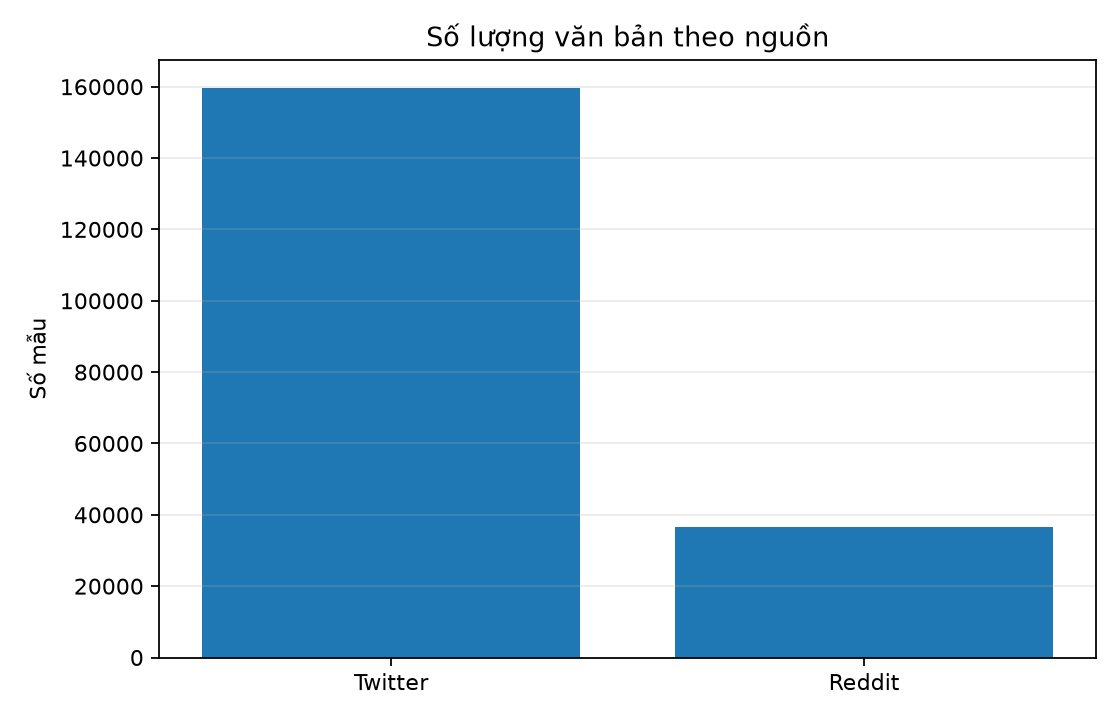

BIỂU ĐỒ: Phân bố 3 nhãn cảm xúc gốc


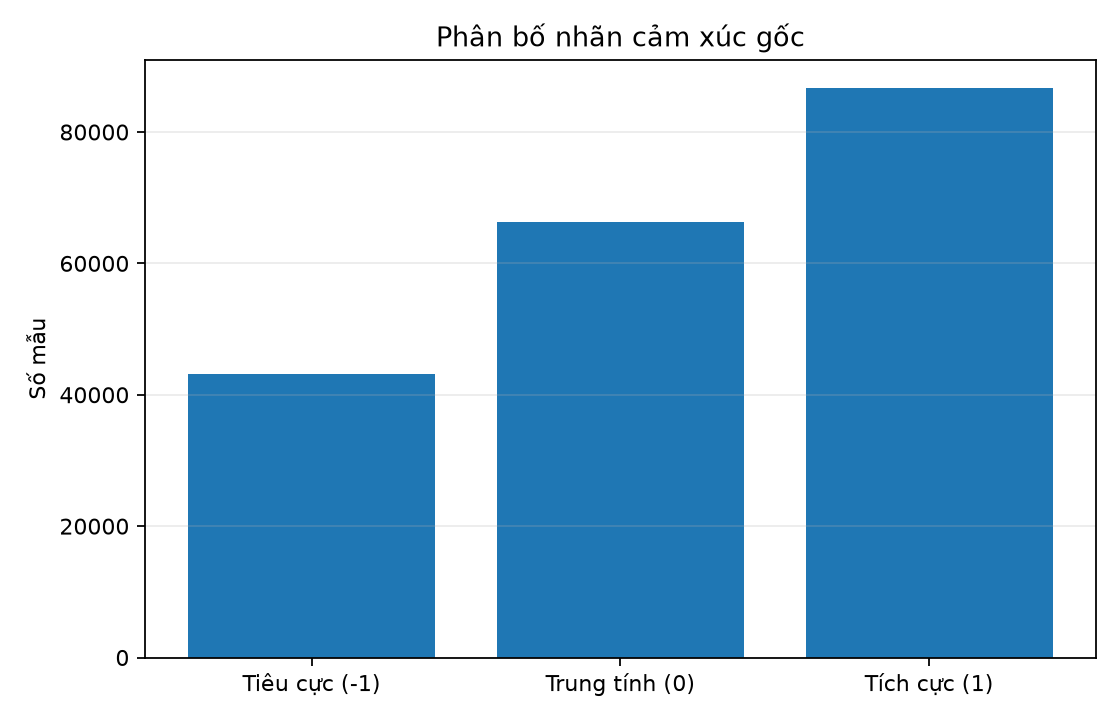

BIỂU ĐỒ: Phân bố 2 nhãn sau ánh xạ


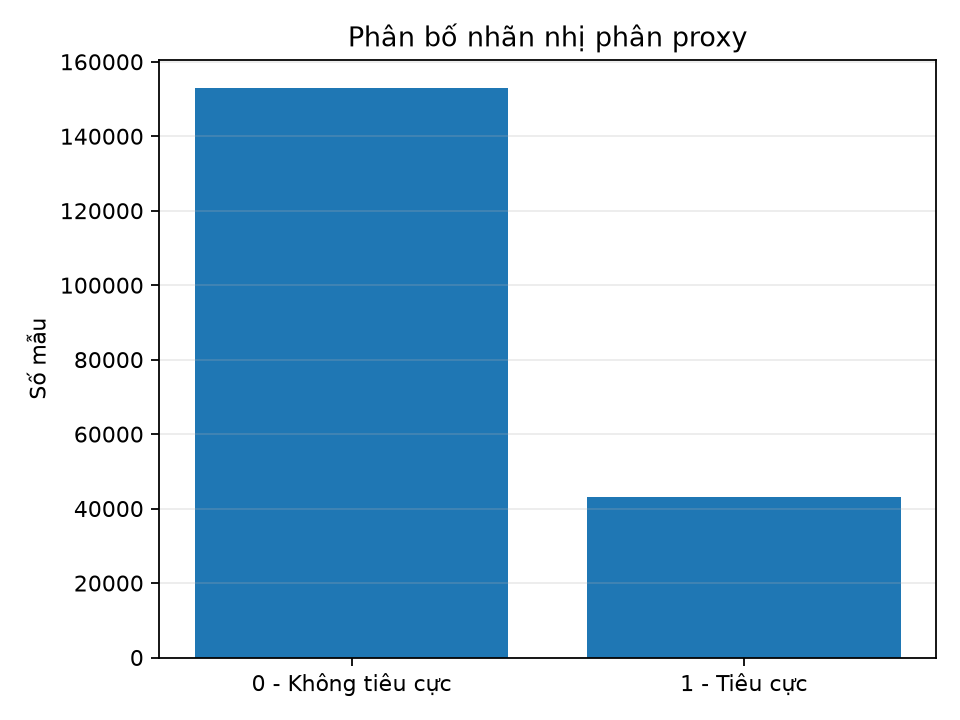

BIỂU ĐỒ: Độ dài văn bản


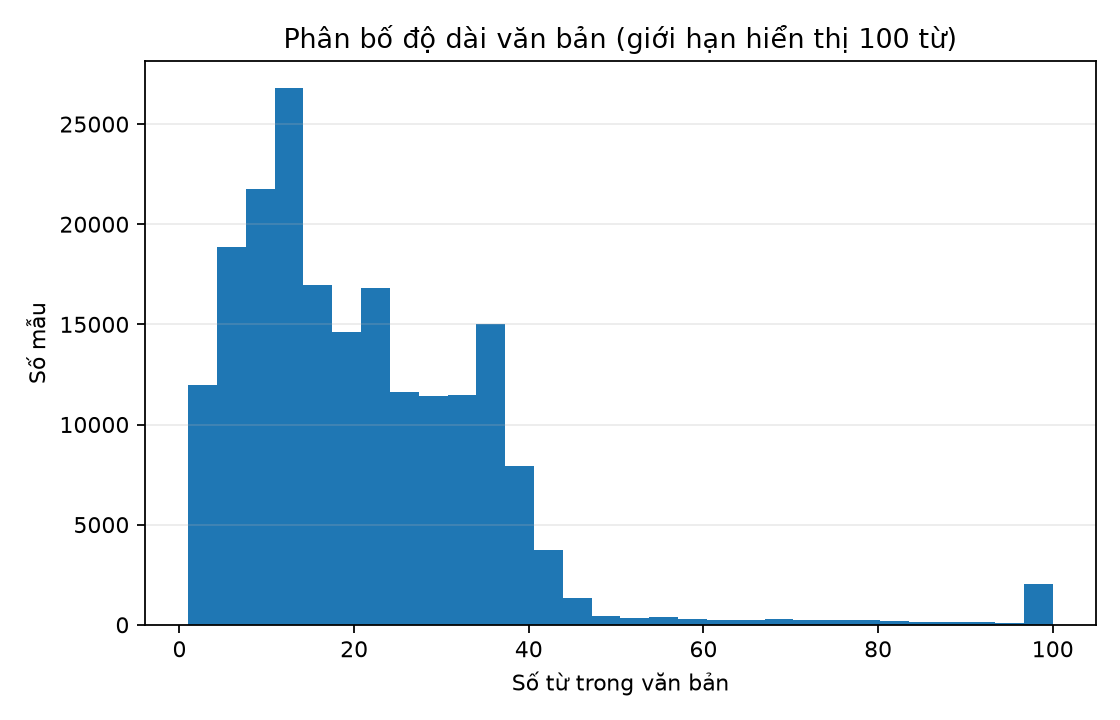

BIỂU ĐỒ: Top 20 từ phổ biến


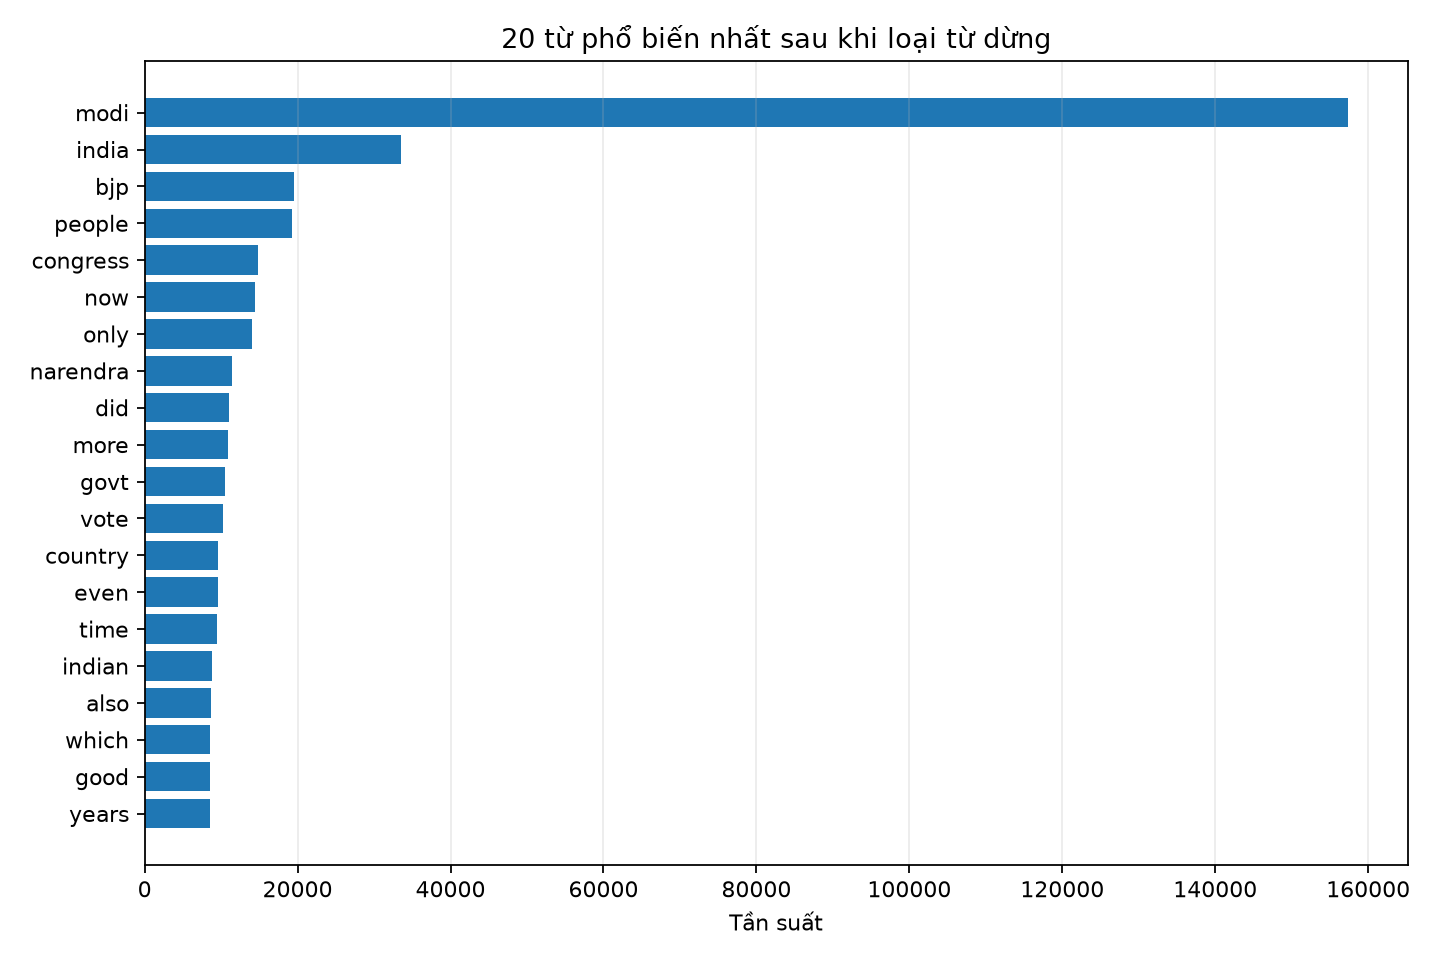

Thống kê số từ: {'mean': 22.002433052792654, 'median': 18.0, 'q1': 10.0, 'q3': 30.0, 'min': 1, 'max': 1308}


,term,frequency
0,modi,157301
1,india,33573
2,bjp,19497
3,people,19225
4,congress,14828
5,now,14379
6,only,14065
7,narendra,11376
8,did,11011
9,more,10964


In [15]:
# Hiển thị rõ từng hình ngay dưới cell, đồng thời vẫn lưu PNG trong outputs/.
from IPython.display import Image, display
for title, name in [
    ('Số mẫu Twitter và Reddit', 'binary_source_distribution.png'),
    ('Phân bố 3 nhãn cảm xúc gốc', 'binary_original_label_distribution.png'),
    ('Phân bố 2 nhãn sau ánh xạ', 'binary_label_distribution.png'),
    ('Độ dài văn bản', 'binary_text_length_distribution.png'),
    ('Top 20 từ phổ biến', 'binary_top20_terms.png'),
]:
    print('BIỂU ĐỒ:', title)
    display(Image(filename=str(OUTPUT / name)))
print('Thống kê số từ:', descriptive_stats['text_length_words'])
display(pd.read_csv(OUTPUT / 'binary_top20_terms.csv').head(20))

**1.7. Top 15 từ ngữ có thể mang sắc thái xúc phạm / thô tục**

Đếm **số lần xuất hiện** và **số bình luận chứa từ** từ danh sách đối chiếu tiếng Anh, trên toàn bộ dữ liệu sạch và riêng nhóm nhãn proxy 1. Thống kê này **không** xác minh nội dung xúc phạm và không phải bộ gán nhãn hate speech. Bảng và biểu đồ được hiển thị trực tiếp, đồng thời xuất CSV/PNG trong `outputs/`.


In [16]:
# Top 15 tu ngu co the xuc pham / tho tuc (danh sach kiem tra co gioi han).
# Luu y: nhan 1 la proxy tu cam xuc tieu cuc, khong phai nhan phan cam da kiem chung.
SUSPECT_TERMS_EN = frozenset({
    'abusive', 'asshole', 'assholes', 'bastard', 'bastards', 'bitch', 'bitches',
    'bullshit', 'crap', 'crappy', 'damn', 'dick', 'dicks', 'dumb',
    'dumbass', 'fool', 'fools', 'fuck', 'fucked', 'fucker', 'fuckers',
    'fucking', 'fucks', 'idiot', 'idiots', 'jerk', 'jerks', 'loser',
    'losers', 'moron', 'morons', 'pathetic', 'scum', 'shit', 'shitty',
    'stfu', 'stupid', 'suck', 'sucks', 'trash', 'ugly', 'worthless',
    'wtf',
})

def suspect_term_frequency(frame: pd.DataFrame, limit: int = 15) -> pd.DataFrame:
    """Count occurrences and documents for each lexicon-matched English token."""
    occurrences, documents = Counter(), Counter()
    for text in frame['text'].fillna('').astype(str):
        tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", text.casefold())
        found = [term for term in tokens if term in SUSPECT_TERMS_EN]
        occurrences.update(found)
        documents.update(set(found))
    rows = [{'tu_ngu': term, 'so_lan_xuat_hien': count,
             'so_binh_luan_chua_tu': documents[term]}
            for term, count in sorted(occurrences.items(), key=lambda item: (-item[1], item[0]))[:limit]]
    return pd.DataFrame(rows, columns=['tu_ngu', 'so_lan_xuat_hien', 'so_binh_luan_chua_tu'])

suspect_all = suspect_term_frequency(clean_df)
suspect_proxy1 = suspect_term_frequency(clean_df.loc[clean_df['label'].eq(1)])
OUTPUT.mkdir(parents=True, exist_ok=True)
suspect_all.to_csv(OUTPUT / 'binary_suspect_terms_all.csv', index=False, encoding='utf-8-sig')
suspect_proxy1.to_csv(OUTPUT / 'binary_suspect_terms_proxy1.csv', index=False, encoding='utf-8-sig')
print('Top 15 tu nghi van trong toan bo du lieu (danh sach doi chieu):')
display(suspect_all)
print('Top 15 tu nghi van trong nhom nhan proxy 1:')
display(suspect_proxy1)

if not suspect_proxy1.empty:
    import matplotlib.pyplot as plt
    plot_df = suspect_proxy1.iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(plot_df['tu_ngu'], plot_df['so_lan_xuat_hien'])
    ax.set(title='Top 15 tu nghi van - nhom nhan proxy 1 (theo tan suat)',
           xlabel='So lan xuat hien', ylabel='Tu ngu doi chieu')
    ax.grid(axis='x', alpha=.2)
    fig.tight_layout()
    fig.savefig(OUTPUT / 'binary_suspect_terms_proxy1.png', dpi=160)
    plt.show()
else:
    print('Khong co tu nao khop danh sach doi chieu trong nhom nay.')


Top 15 tu nghi van trong toan bo du lieu (danh sach doi chieu):


,tu_ngu,so_lan_xuat_hien,so_binh_luan_chua_tu
0,shit,1506,1380
1,stupid,1063,999
2,fool,1017,962
3,fuck,1016,867
4,fucking,746,672
5,idiot,511,498
6,dumb,466,450
7,fools,440,424
8,idiots,422,412
9,damn,406,393


Top 15 tu nghi van trong nhom nhan proxy 1:


,tu_ngu,so_lan_xuat_hien,so_binh_luan_chua_tu
0,shit,924,836
1,stupid,878,825
2,fuck,748,617
3,fucking,538,482
4,idiot,438,426
5,idiots,364,354
6,dumb,339,324
7,fool,293,286
8,pathetic,269,266
9,moron,232,227


C:\Users\vothi\AppData\Local\Temp\ipykernel_8240\3496243472.py:46: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## CÂU 2 — THIẾT KẾ MÔ HÌNH HỌC MÁY (3,0 ĐIỂM)

Chuẩn hóa bằng TF-IDF, chia tập có phân tầng 68% Train / 12% Validation / 20% Test. Không dùng dữ liệu Test để chọn tham số.

In [17]:
# Kiểm tra không trùng văn bản và kiểm tra gần trùng (near-duplicate) giữa Train, Validation, Test.
def assert_splits_disjoint(train_df: pd.DataFrame, val_df: pd.DataFrame, test_df: pd.DataFrame) -> dict:
    sets = [set(part['dedup_key'].astype(str)) for part in (train_df, val_df, test_df)]
    names = [('train', 'validation'), ('train', 'test'), ('validation', 'test')]
    for (left, right), a, b in zip(names, (sets[0], sets[0], sets[1]), (sets[1], sets[2], sets[2])):
        overlap = a.intersection(b)
        assert not overlap, f'Token-normalized duplicate leakage between {left} and {right}: {len(overlap)} keys.'

    # Kiểm tra gần trùng (4-shingle signature / câu dài >= 6 từ sau khi bỏ ký tự ngắn)
    def _near_sig(text: str) -> str:
        words = [w for w in str(text).split() if len(w) > 2]
        if len(words) < 6:
            return ''
        return ' '.join(words[:6]) + '|' + ' '.join(words[-4:])

    train_sigs = {s for s in train_df['dedup_key'].map(_near_sig) if s}
    val_sigs = {s for s in val_df['dedup_key'].map(_near_sig) if s}
    test_sigs = {s for s in test_df['dedup_key'].map(_near_sig) if s}
    return {
        'exact_overlap': 0,
        'near_sig_train_val_overlap': int(len(train_sigs.intersection(val_sigs))),
        'near_sig_train_test_overlap': int(len(train_sigs.intersection(test_sigs))),
        'near_sig_val_test_overlap': int(len(val_sigs.intersection(test_sigs))),
    }

In [18]:
# Hàm tìm ngưỡng tối ưu trên Validation.
def choose_threshold(scores, labels):
    """Choose a binary decision threshold using validation only."""
    scores = np.asarray(scores, dtype=float)
    labels = np.asarray(labels, dtype=int)
    candidates = np.unique(np.r_[0.0, np.quantile(scores, np.linspace(0, 1, 501))])
    best = (float(f1_score(labels, scores > 0, zero_division=0)), 0.0)
    for threshold in candidates:
        f1 = float(f1_score(labels, scores > threshold, zero_division=0))
        if f1 > best[0] + 1e-12 or (abs(f1 - best[0]) <= 1e-12 and abs(threshold) < abs(best[1])):
            best = (f1, float(threshold))
    return best[1], best[0]


In [19]:
# Hàm tính Accuracy, Precision, Recall, F1, PR-AUC và Confusion Matrix.
def binary_scores(y_true, y_pred, y_scores=None):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=[1], zero_division=0)
    res = {
        'samples': int(len(y_true)),
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'precision_1': float(precision[0]), 'recall_1': float(recall[0]), 'f1_1': float(f1[0]),
        'confusion_matrix_labels_0_1': confusion_matrix(y_true, y_pred, labels=[0, 1]).tolist()
    }
    if y_scores is not None:
        res['pr_auc'] = float(average_precision_score(y_true, y_scores))
    return res

In [20]:
# Hàm bootstrap khoảng tin cậy F1 và kiểm định chênh lệch giữa hai mô hình.
def bootstrap_f1_ci(y_true, y_pred, samples=500, seed=SEED):
    rng = np.random.default_rng(seed)
    true = np.asarray(y_true, dtype=int)
    pred = np.asarray(y_pred, dtype=int)
    if len(true) < 20 or samples < 1:
        return None
    scores = []
    n = len(true)
    for _ in range(samples):
        idx = rng.integers(0, n, size=n)
        scores.append(float(f1_score(true[idx], pred[idx], pos_label=1, zero_division=0)))
    return {
        'samples': int(samples), 'seed': int(seed),
        'mean': float(np.mean(scores)),
        'ci_low': float(np.percentile(scores, 2.5)),
        'ci_high': float(np.percentile(scores, 97.5))
    }

def paired_bootstrap_f1_diff(y_true, pred_a, pred_b, samples=500, seed=SEED):
    rng = np.random.default_rng(seed)
    true = np.asarray(y_true, dtype=int)
    pa = np.asarray(pred_a, dtype=int)
    pb = np.asarray(pred_b, dtype=int)
    n = len(true)
    diffs = []
    for _ in range(samples):
        idx = rng.integers(0, n, size=n)
        fa = f1_score(true[idx], pa[idx], pos_label=1, zero_division=0)
        fb = f1_score(true[idx], pb[idx], pos_label=1, zero_division=0)
        diffs.append(float(fa - fb))
    diffs = np.asarray(diffs)
    ci_low, ci_high = float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))
    significant = bool(ci_low > 0 or ci_high < 0)
    return {
        'mean_diff': float(np.mean(diffs)),
        'ci_low': ci_low,
        'ci_high': ci_high,
        'statistically_significant_95pct': significant,
    }

In [21]:
# Hiển thị tiến độ chạy.
def emit_progress(percent: int, stage: str) -> None:
    print(f'PROGRESS|{int(percent)}|{stage}', flush=True)


In [22]:
# Pipeline TF-IDF + LinearSVC.
def make_pipeline(max_features: int, min_df: int, estimator, memory=None):
    return Pipeline([
        ('tfidf', TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=min_df,
                                  max_features=max_features, sublinear_tf=True, dtype=np.float32)),
        ('classifier', estimator)
    ], memory=memory)


In [23]:
# Lưu ba tập đã chia và mã băm.
def _save_split(frame: pd.DataFrame, path: Path) -> str:
    frame.to_csv(path, index=False, encoding='utf-8-sig')
    return sha256_file(path)


**2.1. Chia dữ liệu Train / Validation / Test**

In [24]:
# Tham số mặc định của lần chạy đầy đủ
out = OUTPUT
data_dir = DATA
validation_size = 0.15
max_features = 40000
max_iter = 3000
bootstrap_samples = 500
tuning_fraction = 1.0
c_values = DEFAULT_C_VALUES
out = Path(out)
data_dir = Path(data_dir)
stale_baseline = out / 'binary_baseline_comparison.csv'
if stale_baseline.exists():
    stale_baseline.unlink()

emit_progress(2, 'Đang đọc Twitter_Data.csv và Reddit_Data.csv')
df, stats = clean_df.copy(), source_stats.copy()
df['label'] = df['category'].map(BINARY_MAPPING).astype(int)
ycol, mapping = 'label', BINARY_NAMES
stats['binary_mapping'] = {str(k): int(v) for k, v in BINARY_MAPPING.items()}
stats['binary_label_names'] = {str(k): v for k, v in BINARY_NAMES.items()}
data_summary = save_data_summary(df, out)
descriptive_stats = save_descriptive_outputs(df, out)
stats['binary_label_counts'] = {str(int(k)): int(v) for k, v in df['label'].value_counts().sort_index().items()}
stats['binary_label_percentages'] = {str(int(k)): round(float(v / len(df) * 100), 3)
                                     for k, v in df['label'].value_counts().sort_index().items()}

required_sources = {'Twitter_Data.csv', 'Reddit_Data.csv'}
actual_sources = set(df['source'].astype(str).unique())
if not required_sources.issubset(actual_sources):
    missing_sources = sorted(required_sources - actual_sources)
    raise ValueError(f"Không đủ dữ liệu từ cả hai nguồn. Thiếu hoặc không còn mẫu hợp lệ: {missing_sources}")
counts = df[ycol].value_counts()
if len(counts) < 2 or counts.min() < 10:
    raise ValueError('Cần ít nhất 10 mẫu hợp lệ cho mỗi lớp trước khi chia dữ liệu.')

emit_progress(8, f"Đã gộp dữ liệu hai nguồn: {len(df):,} mẫu; đang chia train/validation/test phân tầng theo nhãn và nguồn")
strat_key = df[ycol].astype(str) + '__' + df['source'].astype(str)
idx_train_val, idx_test = train_test_split(
    np.arange(len(df)), test_size=0.20, random_state=SEED, stratify=strat_key)
idx_train, idx_val = train_test_split(
    idx_train_val, test_size=validation_size, random_state=SEED,
    stratify=strat_key.iloc[idx_train_val])
train_df, val_df, test_df = (
    df.iloc[idx].copy().reset_index(drop=True)
    for idx in (idx_train, idx_val, idx_test)
)
leakage_report = assert_splits_disjoint(train_df, val_df, test_df)
print('Kiểm tra rò rỉ dữ liệu giữa các tập:', leakage_report)

split_dir = out / 'splits' / 'binary'
split_dir.mkdir(parents=True, exist_ok=True)
split_hashes = {
    'train': _save_split(train_df, split_dir / 'train.csv'),
    'validation': _save_split(val_df, split_dir / 'validation.csv'),
    'test': _save_split(test_df, split_dir / 'test.csv')
}

PROGRESS|2|Đang đọc Twitter_Data.csv và Reddit_Data.csv
PROGRESS|8|Đã gộp dữ liệu hai nguồn: 196,050 mẫu; đang chia train/validation/test phân tầng theo nhãn và nguồn
Kiểm tra rò rỉ dữ liệu giữa các tập: {'exact_overlap': 0, 'near_sig_train_val_overlap': 119, 'near_sig_train_test_overlap': 189, 'near_sig_val_test_overlap': 55}


**2.2. Kiểm tra phân bố nhãn của ba tập**

In [25]:
# Hiển thị tỷ lệ từng nhãn trong ba tập để chứng minh chia phân tầng.
display(pd.DataFrame({
    'Train': train_df['label'].value_counts(normalize=True),
    'Validation': val_df['label'].value_counts(normalize=True),
    'Test': test_df['label'].value_counts(normalize=True),
}).sort_index().round(4))
print('Số mẫu:', len(train_df), len(val_df), len(test_df))

,Train,Validation,Test
label,,,
0,0.7799,0.7799,0.7799
1,0.2201,0.2201,0.2201


Số mẫu: 133314 23526 39210


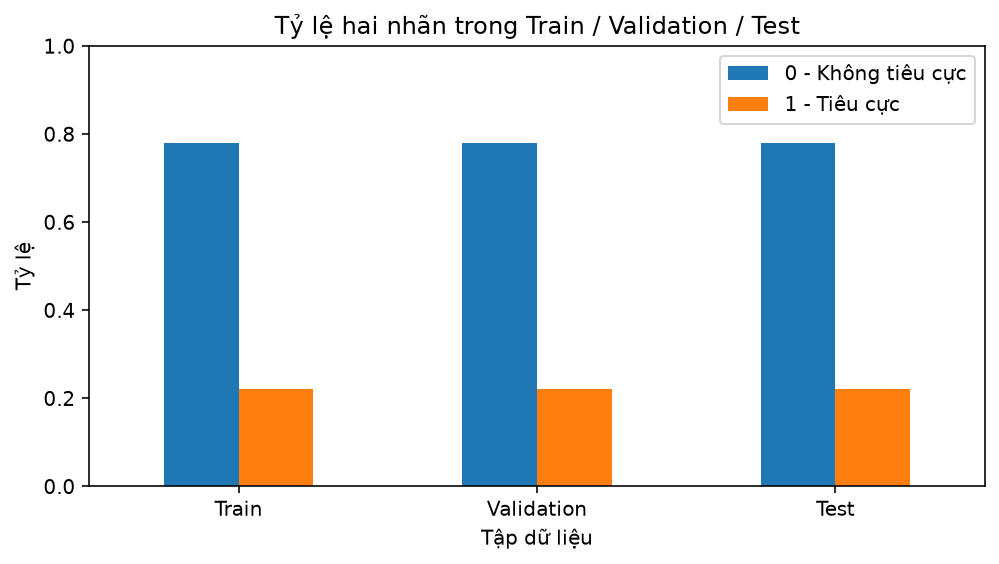

In [26]:
# CÂU 2: trực quan tỷ lệ nhãn trong từng tập sau chia phân tầng.
import matplotlib.pyplot as plt
split_plot = pd.DataFrame({
    'Train': train_df['label'].value_counts(normalize=True),
    'Validation': val_df['label'].value_counts(normalize=True),
    'Test': test_df['label'].value_counts(normalize=True),
}).fillna(0).T
ax = split_plot[[0, 1]].plot(kind='bar', figsize=(7, 4), rot=0)
ax.set(title='Tỷ lệ hai nhãn trong Train / Validation / Test', ylabel='Tỷ lệ', xlabel='Tập dữ liệu')
ax.legend(['0 - Không tiêu cực', '1 - Tiêu cực'])
ax.set_ylim(0, 1)
plt.tight_layout()

from io import BytesIO
_buf = BytesIO()
plt.savefig(_buf, format='png', dpi=145, bbox_inches='tight')
display(Image(data=_buf.getvalue()))
plt.close()

**2.3. Xử lý mất cân bằng:** Lớp 1 chiếm khoảng 22% sau ánh xạ. Notebook giữ phân bố thật, dùng `stratify` khi chia tập và không tự nhân bản mẫu. Để có bằng chứng, Câu 3 chạy thêm đối chứng `LinearSVC(class_weight="balanced")` trên cùng TF-IDF và cùng split; so sánh Precision, Recall, F1 trên Validation/Test. Chỉ chọn cách cân bằng nếu cải thiện phù hợp, không mặc định SMOTE.


## CÂU 3 — SO SÁNH, TỐI ƯU VÀ CHẠY THỬ MÔ HÌNH (3,0 ĐIỂM)

So sánh **Multinomial Naive Bayes** và **LinearSVC** trên cùng dữ liệu; tối ưu C bằng 5-fold CV, chọn ngưỡng trên Validation, đánh giá Test độc lập.

In [27]:
# Tối ưu alpha của Naive Bayes trên Validation; không dùng Test để chọn tham số.
def fit_naive_bayes_baseline(train_df, val_df, test_df, fitted_tfidf, alpha_values=(0.1, 0.5, 1.0, 2.0)):
    X_train = fitted_tfidf.transform(train_df['text'])
    X_val = fitted_tfidf.transform(val_df['text'])
    X_test = fitted_tfidf.transform(test_df['text'])
    best = None
    for alpha in alpha_values:
        estimator = MultinomialNB(alpha=float(alpha))
        estimator.fit(X_train, train_df['label'])
        positive_index = list(estimator.classes_).index(1)
        val_scores = estimator.predict_proba(X_val)[:, positive_index]
        ap = average_precision_score(val_df['label'], val_scores)
        if best is None or ap > best['average_precision']:
            best = {'model': estimator, 'alpha': float(alpha), 'val_scores': val_scores,
                    'average_precision': float(ap)}
    threshold, validation_f1 = choose_threshold(best['val_scores'], val_df['label'])
    positive_index = list(best['model'].classes_).index(1)
    test_scores = best['model'].predict_proba(X_test)[:, positive_index]
    test_predictions = (test_scores > threshold).astype(int)
    return best['model'], best['alpha'], threshold, validation_f1, best['average_precision'], test_scores, test_predictions


# Tối ưu C của Logistic Regression trên Validation bằng Average Precision.
def fit_logistic_regression_baseline(train_df, val_df, test_df, fitted_tfidf, c_values=(0.1, 1.0)):
    X_train = fitted_tfidf.transform(train_df['text'])
    X_val = fitted_tfidf.transform(val_df['text'])
    X_test = fitted_tfidf.transform(test_df['text'])
    best = None
    for c_value in c_values:
        estimator = LogisticRegression(C=float(c_value), solver='liblinear', max_iter=500,
                                       random_state=SEED)
        estimator.fit(X_train, train_df['label'])
        positive_index = list(estimator.classes_).index(1)
        val_scores = estimator.predict_proba(X_val)[:, positive_index]
        ap = average_precision_score(val_df['label'], val_scores)
        if best is None or ap > best['average_precision']:
            best = {'model': estimator, 'C': float(c_value), 'val_scores': val_scores,
                    'average_precision': float(ap)}
    threshold, validation_f1 = choose_threshold(best['val_scores'], val_df['label'])
    positive_index = list(best['model'].classes_).index(1)
    test_scores = best['model'].predict_proba(X_test)[:, positive_index]
    test_predictions = (test_scores > threshold).astype(int)
    return best['model'], best['C'], threshold, validation_f1, best['average_precision'], test_scores, test_predictions


# Thử nghiệm class_weight='balanced' trên cùng TF-IDF và cùng tập chia.
def fit_balanced_svm_experiment(train_df, val_df, test_df, fitted_tfidf, c_value, max_iter):
    X_train = fitted_tfidf.transform(train_df['text'])
    X_val = fitted_tfidf.transform(val_df['text'])
    X_test = fitted_tfidf.transform(test_df['text'])
    estimator = LinearSVC(C=float(c_value), class_weight='balanced', max_iter=max_iter, random_state=SEED)
    estimator.fit(X_train, train_df['label'])
    val_scores = estimator.decision_function(X_val)
    threshold, validation_f1 = choose_threshold(val_scores, val_df['label'])
    test_scores = estimator.decision_function(X_test)
    predictions = (test_scores > threshold).astype(int)
    return estimator, threshold, validation_f1, test_scores, predictions


In [28]:
# Hàm 5-fold Cross-validation tìm C cho LinearSVC.
def tune_svm_c(train_df: pd.DataFrame, max_features: int, max_iter: int,
               tuning_fraction: float = 1.0, c_values=DEFAULT_C_VALUES):
    """Select C by average precision using stratified CV on train only.

    Full train subset is used by default; tuning_fraction<1 is only an
    explicit speed/diagnostic override and must not be used for reporting.
    """
    if not 0 < tuning_fraction <= 1:
        raise ValueError('tuning_fraction must be in (0, 1].')
    min_df = 2 if len(train_df) >= 100 else 1
    n_tune = min(len(train_df), max(100, int(round(len(train_df) * tuning_fraction))))
    if n_tune < len(train_df):
        tuning_df, _ = train_test_split(train_df, train_size=n_tune, random_state=SEED,
                                        stratify=train_df['label'])
    else:
        tuning_df = train_df.copy()
    min_class = int(tuning_df['label'].value_counts().min())
    n_splits = min(5, min_class)
    if n_splits < 2:
        raise ValueError('Not enough examples per class in the tuning subset for cross-validation.')
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    # Cache TF-IDF fit/transform for each CV fold so changing C does not
    # re-vectorize the same fold four times. The temporary cache is removed
    # automatically after model selection and is not part of the deliverable.
    with tempfile.TemporaryDirectory(prefix='textsense_cv_cache_') as cache_dir:
        memory = Memory(location=cache_dir, verbose=0)
        base = make_pipeline(max_features, min_df,
                             LinearSVC(max_iter=max_iter, random_state=SEED),
                             memory=memory)
        search = GridSearchCV(base, {'classifier__C': list(c_values)}, scoring='average_precision', cv=cv,
                              refit=True, n_jobs=1, return_train_score=False, error_score='raise')
        search.fit(tuning_df['text'], tuning_df['label'])
        # Detach the temporary cache reference before the directory is removed.
        best_c = float(search.best_params_['classifier__C'])
    table = pd.DataFrame({
        'C': [float(v) for v in search.cv_results_['param_classifier__C']],
        'mean_cv_average_precision': search.cv_results_['mean_test_score'].astype(float),
        'std_cv_average_precision': search.cv_results_['std_test_score'].astype(float),
        'rank': search.cv_results_['rank_test_score'].astype(int)
    }).sort_values(['rank', 'C']).reset_index(drop=True)
    return best_c, table, len(tuning_df), n_splits


**3.1. Tối ưu tham số C và huấn luyện LinearSVC**

In [29]:
# Chọn C bằng Cross Validation rồi fit LinearSVC trên toàn bộ Train.
min_df = 2 if len(train_df) >= 100 else 1
emit_progress(12, 'Đang chọn C bằng average precision, Stratified 5-fold CV trên toàn bộ train')
best_c, cv_table, tuning_rows, cv_splits = tune_svm_c(
    train_df, max_features, max_iter, tuning_fraction=tuning_fraction, c_values=c_values)
cv_table.to_csv(out / 'binary_cv_results.csv', index=False, encoding='utf-8-sig')
classifier = LinearSVC(C=best_c, max_iter=max_iter, random_state=SEED)

emit_progress(50, f'Đang fit TF-IDF + LinearSVC với C={best_c:g}')
pipeline = make_pipeline(max_features, min_df, classifier)
pipeline.fit(train_df['text'], train_df[ycol])

PROGRESS|12|Đang chọn C bằng average precision, Stratified 5-fold CV trên toàn bộ train
PROGRESS|50|Đang fit TF-IDF + LinearSVC với C=1


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",40000
,"dtype dtype: dtype, default=float64Type of the matrix returned by fit_transform() or transform().",<class 'numpy.float32'>
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True


In [30]:
# Xem kết quả Cross-validation từ biến hiện có.
display(cv_table if 'cv_table' in globals() else pd.read_csv(OUTPUT / 'binary_cv_results.csv'))

,C,mean_cv_average_precision,std_cv_average_precision,rank
0,1.0,0.925138,0.003084,1
1,2.0,0.923703,0.002671,2
2,0.5,0.921273,0.003598,3
3,5.0,0.915477,0.002204,4


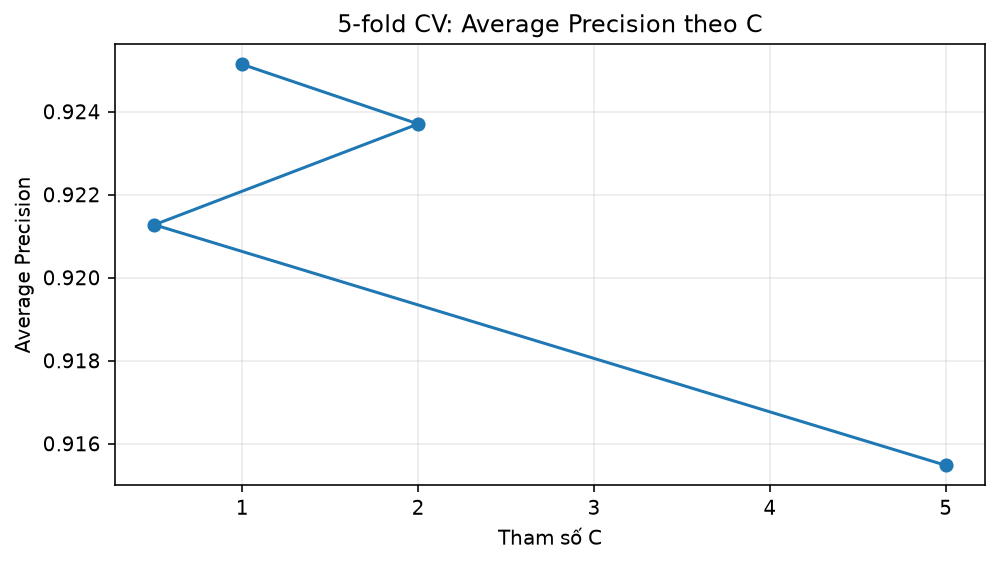

In [31]:
# CÂU 3: biểu đồ mức điểm Average Precision của từng giá trị C.
import matplotlib.pyplot as plt
cv_plot = cv_table.copy()
if 'param_classifier__C' in cv_plot.columns:
    c_axis = cv_plot['param_classifier__C'].astype(float)
elif 'param_model__C' in cv_plot.columns:
    c_axis = cv_plot['param_model__C'].astype(float)
elif 'C' in cv_plot.columns:
    c_axis = cv_plot['C'].astype(float)
else:
    c_axis = None
score_col = next((k for k in ['mean_cv_average_precision', 'mean_test_score', 'mean_average_precision', 'mean_AP'] if k in cv_plot.columns), None)
if c_axis is not None and score_col is not None:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(c_axis, cv_plot[score_col], marker='o')
    ax.set(title='5-fold CV: Average Precision theo C', xlabel='Tham số C', ylabel='Average Precision')
    ax.grid(alpha=.25)
    plt.tight_layout(); 
    from io import BytesIO
    _buf = BytesIO()
    plt.savefig(_buf, format='png', dpi=145, bbox_inches='tight')
    display(Image(data=_buf.getvalue()))
    plt.close()
else:
    print('Xem bảng CV phía trên để đối chiếu các giá trị C.')

**3.2. Chọn ngưỡng phân loại trên Validation**

In [32]:
# Tính decision score, tìm ngưỡng từ Validation và dự đoán Test.
emit_progress(72, 'Đang chọn ngưỡng quyết định chỉ từ validation')
svm_val_scores = pipeline.decision_function(val_df['text'])
threshold, validation_f1 = choose_threshold(svm_val_scores, val_df[ycol])
svm_val_predictions = (svm_val_scores > threshold).astype(int)
svm_validation_metrics = binary_scores(val_df[ycol], svm_val_predictions, svm_val_scores)
test_scores = pipeline.decision_function(test_df['text'])
baseline_threshold_predictions = (test_scores > 0.0).astype(int)
predictions = (test_scores > threshold).astype(int)

PROGRESS|72|Đang chọn ngưỡng quyết định chỉ từ validation


**3.3. Huấn luyện Naive Bayes và so sánh công bằng**

In [33]:
# So sánh công bằng các baseline (All-0, VADER) và 3 thuật toán ML trên cùng Train/Validation/Test.
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

emit_progress(76, 'Đang đánh giá baseline (All-0, VADER), Naive Bayes và Logistic Regression')
fitted_tfidf = pipeline.named_steps['tfidf']

# 1) Majority class baseline (dự đoán toàn lớp 0)
maj_val_pred = np.zeros(len(val_df), dtype=int)
maj_test_pred = np.zeros(len(test_df), dtype=int)
maj_val_scores = np.zeros(len(val_df), dtype=float)
maj_test_scores = np.zeros(len(test_df), dtype=float)
maj_validation_metrics = binary_scores(val_df[ycol], maj_val_pred, maj_val_scores)
maj_test_metrics = binary_scores(test_df[ycol], maj_test_pred, maj_test_scores)

# 2) VADER lexicon baseline (dùng -compound làm điểm tiêu cực, chọn ngưỡng trên Validation)
_vader = SentimentIntensityAnalyzer()
vader_val_scores = np.array([-_vader.polarity_scores(t)['compound'] for t in val_df['text']], dtype=float)
vader_threshold, vader_val_f1 = choose_threshold(vader_val_scores, val_df[ycol])
vader_val_pred = (vader_val_scores > vader_threshold).astype(int)
vader_validation_metrics = binary_scores(val_df[ycol], vader_val_pred, vader_val_scores)
vader_test_scores = np.array([-_vader.polarity_scores(t)['compound'] for t in test_df['text']], dtype=float)
vader_predictions = (vader_test_scores > vader_threshold).astype(int)
vader_test_metrics = binary_scores(test_df[ycol], vader_predictions, vader_test_scores)

# 3) MultinomialNB
nb_model, nb_alpha, nb_threshold, nb_validation_f1, nb_validation_ap, nb_test_scores, nb_predictions = fit_naive_bayes_baseline(
    train_df, val_df, test_df, fitted_tfidf)
nb_val_scores = nb_model.predict_proba(fitted_tfidf.transform(val_df['text']))[:, list(nb_model.classes_).index(1)]
nb_val_predictions = (nb_val_scores > nb_threshold).astype(int)
nb_validation_metrics = binary_scores(val_df[ycol], nb_val_predictions, nb_val_scores)
nb_test_metrics = binary_scores(test_df[ycol], nb_predictions, nb_test_scores)

# 4) LogisticRegression
lr_model, lr_c, lr_threshold, lr_validation_f1, lr_validation_ap, lr_test_scores, lr_predictions = fit_logistic_regression_baseline(
    train_df, val_df, test_df, fitted_tfidf)
lr_val_scores = lr_model.predict_proba(fitted_tfidf.transform(val_df['text']))[:, list(lr_model.classes_).index(1)]
lr_validation_metrics = binary_scores(val_df[ycol], (lr_val_scores > lr_threshold).astype(int), lr_val_scores)
lr_test_metrics = binary_scores(test_df[ycol], lr_predictions, lr_test_scores)

# 5) LinearSVC (mô hình chính) & 6) LinearSVC class_weight='balanced'
balanced_svm, balanced_threshold, balanced_validation_f1, balanced_test_scores, balanced_predictions = fit_balanced_svm_experiment(
    train_df, val_df, test_df, fitted_tfidf, best_c, max_iter)
balanced_val_scores = balanced_svm.decision_function(fitted_tfidf.transform(val_df['text']))
balanced_validation_metrics = binary_scores(val_df[ycol], (balanced_val_scores > balanced_threshold).astype(int), balanced_val_scores)
balanced_test_metrics = binary_scores(test_df[ycol], balanced_predictions, balanced_test_scores)
svm_test_metrics = binary_scores(test_df[ycol], predictions, test_scores)

# Bootstrap 95% CI cho F1 lớp 1 và kiểm định chênh lệch có cặp (paired bootstrap)
model_preds_for_ci = {
    'Majority (all 0)': maj_test_pred,
    'VADER (lexicon)': vader_predictions,
    'MultinomialNB + TF-IDF': nb_predictions,
    'LogisticRegression + TF-IDF': lr_predictions,
    'LinearSVC + TF-IDF (mô hình chính)': predictions,
    "LinearSVC + TF-IDF (class_weight=balanced)": balanced_predictions,
}
bootstrap_by_model = {
    name: bootstrap_f1_ci(test_df[ycol], pred, bootstrap_samples, SEED)
    for name, pred in model_preds_for_ci.items()
}
significance_tests = {
    'LinearSVC_vs_LogisticRegression': paired_bootstrap_f1_diff(test_df[ycol], predictions, lr_predictions, bootstrap_samples, SEED),
    'LinearSVC_vs_MultinomialNB': paired_bootstrap_f1_diff(test_df[ycol], predictions, nb_predictions, bootstrap_samples, SEED),
    'LinearSVC_vs_VADER': paired_bootstrap_f1_diff(test_df[ycol], predictions, vader_predictions, bootstrap_samples, SEED),
}
pd.DataFrame([{'comparison': k, **v} for k, v in significance_tests.items()]).to_csv(
    out / 'binary_model_significance.csv', index=False, encoding='utf-8-sig')

comparison_rows = []
for model_name, model_threshold, val_metrics, test_metrics, tuning_note in [
    ('Majority (all 0)', 0.0, maj_validation_metrics, maj_test_metrics, 'Mốc dự đoán toàn lớp đa số 0'),
    ('VADER (lexicon)', vader_threshold, vader_validation_metrics, vader_test_metrics, f'Ngưỡng -compound={vader_threshold:.4f} chọn trên Validation'),
    ('MultinomialNB + TF-IDF', nb_threshold, nb_validation_metrics, nb_test_metrics, f'alpha={nb_alpha:g}; chọn theo AP validation={nb_validation_ap:.4f}'),
    ('LogisticRegression + TF-IDF', lr_c if False else lr_threshold, lr_validation_metrics, lr_test_metrics, f'C={lr_c:g}; chọn theo AP validation={lr_validation_ap:.4f}'),
    ('LinearSVC + TF-IDF (mô hình chính)', threshold, svm_validation_metrics, svm_test_metrics, f'C={best_c:g}; chọn bằng 5-fold CV trên Train'),
    ("LinearSVC + TF-IDF (class_weight=balanced)", balanced_threshold, balanced_validation_metrics, balanced_test_metrics, 'Thử nghiệm cân bằng trọng số; C giữ bằng mô hình chính')
]:
    ci = bootstrap_by_model[model_name]
    comparison_rows.append({
        'model': model_name, 'threshold': float(model_threshold), 'tuning': tuning_note,
        **{f'validation_{key}': value for key, value in val_metrics.items() if key != 'confusion_matrix_labels_0_1'},
        **{f'test_{key}': value for key, value in test_metrics.items() if key != 'confusion_matrix_labels_0_1'},
        'test_f1_ci_low': ci['ci_low'] if ci else None,
        'test_f1_ci_high': ci['ci_high'] if ci else None,
    })
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(out / 'binary_model_comparison.csv', index=False, encoding='utf-8-sig')

class_weight_experiment = pd.DataFrame([
    {'setting': 'LinearSVC mặc định', **svm_test_metrics},
    {'setting': "LinearSVC class_weight='balanced'", **balanced_test_metrics}
])
class_weight_experiment.to_csv(out / 'binary_class_weight_experiment.csv', index=False, encoding='utf-8-sig')
print(f'Naive Bayes alpha được chọn trên Validation: {nb_alpha:g}')
print(f'Logistic Regression C được chọn trên Validation: {lr_c:g}')
display(comparison[['model', 'test_precision_1', 'test_recall_1', 'test_f1_1', 'test_pr_auc', 'test_f1_ci_low', 'test_f1_ci_high', 'test_accuracy']])
print('Kiểm định ý nghĩa thống kê (Paired Bootstrap 95% CI cho hiệu số F1):')
display(pd.DataFrame([{'So sánh': k, **v} for k, v in significance_tests.items()]))
display(class_weight_experiment)

PROGRESS|76|Đang đánh giá baseline (All-0, VADER), Naive Bayes và Logistic Regression
Naive Bayes alpha được chọn trên Validation: 0.5
Logistic Regression C được chọn trên Validation: 1


,model,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_f1_ci_low,test_f1_ci_high,test_accuracy
0,Majority (all 0),0.000000,0.000000,0.000000,0.220071,0.000000,0.000000,0.779929
1,VADER (lexicon),0.427804,0.618380,0.505734,0.434465,0.496661,0.514027,0.733996
2,MultinomialNB + TF-IDF,0.643952,0.696489,0.669191,0.729126,0.661511,0.677274,0.848457
3,LogisticRegression + TF-IDF,0.806365,0.869162,0.836587,0.892893,0.830886,0.842150,0.925274
4,LinearSVC + TF-IDF (mô hình chính),0.862849,0.888747,0.875607,0.933606,0.869876,0.880521,0.944427
5,LinearSVC + TF-IDF (class_weight=balanced),0.840169,0.899757,0.868942,0.927232,0.863523,0.873952,0.940270


Kiểm định ý nghĩa thống kê (Paired Bootstrap 95% CI cho hiệu số F1):


,So sánh,mean_diff,ci_low,ci_high,statistically_significant_95pct
0,LinearSVC_vs_LogisticRegression,0.039155,0.034859,0.043343,True
1,LinearSVC_vs_MultinomialNB,0.206371,0.199103,0.214150,True
2,LinearSVC_vs_VADER,0.370043,0.360762,0.378442,True


,setting,samples,accuracy,precision_1,recall_1,f1_1,confusion_matrix_labels_0_1,pr_auc
0,LinearSVC mặc định,39210,0.944427,0.862849,0.888747,0.875607,"[[29362, 1219], [960, 7669]]",0.933606
1,LinearSVC class_weight='balanced',39210,0.940270,0.840169,0.899757,0.868942,"[[29104, 1477], [865, 7764]]",0.927232


In [34]:
# Bảng so sánh ba thuật toán và biến thể cân bằng; biến comparison được tạo ở cell ngay phía trên.
# Chạy notebook tuần tự từ trên xuống để bảo đảm các mô hình đã được fit.
display(comparison)

,model,threshold,tuning,validation_samples,validation_accuracy,validation_precision_1,validation_recall_1,validation_f1_1,validation_pr_auc,test_samples,test_accuracy,test_precision_1,test_recall_1,test_f1_1,test_pr_auc,test_f1_ci_low,test_f1_ci_high
0,Majority (all 0),0.000000,Mốc dự đoán toàn lớp đa số 0,23526,0.779946,0.000000,0.000000,0.000000,0.220054,39210,0.779929,0.000000,0.000000,0.000000,0.220071,0.000000,0.000000
1,VADER (lexicon),0.000000,Ngưỡng -compound=0.0000 chọn trên Validation,23526,0.734166,0.428248,0.620823,0.506860,0.433997,39210,0.733996,0.427804,0.618380,0.505734,0.434465,0.496661,0.514027
2,MultinomialNB + TF-IDF,0.281996,alpha=0.5; chọn theo AP validation=0.7312,23526,0.850336,0.646652,0.705235,0.674674,0.731212,39210,0.848457,0.643952,0.696489,0.669191,0.729126,0.661511,0.677274
3,LogisticRegression + TF-IDF,0.295805,C=1; chọn theo AP validation=0.8979,23526,0.926889,0.808716,0.874638,0.840386,0.897904,39210,0.925274,0.806365,0.869162,0.836587,0.892893,0.830886,0.842150
4,LinearSVC + TF-IDF (mô hình chính),-0.192201,C=1; chọn bằng 5-fold CV trên Train,23526,0.946102,0.867595,0.891057,0.879169,0.937160,39210,0.944427,0.862849,0.888747,0.875607,0.933606,0.869876,0.880521
5,LinearSVC + TF-IDF (class_weight=balanced),0.000000,Thử nghiệm cân bằng trọng số; C giữ bằng mô hì...,23526,0.941512,0.844356,0.900135,0.871354,0.931191,39210,0.940270,0.840169,0.899757,0.868942,0.927232,0.863523,0.873952


In [35]:
# Biểu đồ so sánh F1 lớp 1 và PR-AUC trên Test của các mô hình.
import matplotlib.pyplot as plt
comparison_plot = pd.read_csv(OUTPUT / 'binary_model_comparison.csv')
if 'test_f1_1' in comparison_plot.columns:
    labels = comparison_plot['model'].tolist()
    fig, ax = plt.subplots(figsize=(10.5, 4.8))
    values = comparison_plot['test_f1_1'].to_numpy()
    bars = ax.bar(range(len(labels)), values)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=15, ha='right')
    ax.set(ylim=(0, 1.05), ylabel='F1 lớp 1 (Tiêu cực) trên Test', title='So sánh F1 lớp 1 trên Test giữa các baseline và mô hình')
    ax.grid(axis='y', alpha=0.25)
    for bar, v in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.015, f'{v:.4f}', ha='center', va='bottom', fontsize=9)
    fig.tight_layout()
    fig.savefig(OUTPUT / 'binary_model_comparison.png', dpi=160)
    plt.show()

C:\Users\vothi\AppData\Local\Temp\ipykernel_8240\4068266735.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [36]:
# Hàm tạo ma trận nhầm lẫn, PR Curve và phân tích lỗi.
def save_binary_diagnostics(out: Path, test_df: pd.DataFrame, y_true, y_pred, scores,
                            threshold: float, pipeline: Pipeline, mapping: dict) -> dict:
    """Write PR curve, misclassification analysis and linear SVM token coefficients."""
    out.mkdir(parents=True, exist_ok=True)
    precision, recall, thresholds = precision_recall_curve(y_true, scores, pos_label=1)
    pr_frame = pd.DataFrame({
        'recall': recall, 'precision': precision,
        'threshold': np.r_[thresholds, np.nan]
    })
    pr_path = out / 'binary_pr_curve.csv'
    pr_frame.to_csv(pr_path, index=False, encoding='utf-8-sig')

    try:
        import matplotlib
        matplotlib.use('Agg')
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(figsize=(7.2, 5.2))
        ap_value = average_precision_score(y_true, scores)
        ax.plot(recall, precision, label=f'LinearSVC (AP={ap_value:.3f})')
        ax.set(xlabel='Recall lớp 1 (Tiêu cực)', ylabel='Precision lớp 1 (Tiêu cực)',
               title='Precision–Recall curve trên tập test')
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.02)
        ax.grid(True, alpha=0.25)
        ax.legend(loc='best')
        fig.tight_layout()
        fig.savefig(out / 'binary_pr_curve.png', dpi=160)
        plt.close(fig)

        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
        fig, ax = plt.subplots(figsize=(5.8, 5.0))
        image = ax.imshow(cm, cmap='Blues')
        ax.set(xticks=[0, 1], yticks=[0, 1],
               xticklabels=['0 - Không tiêu cực', '1 - Tiêu cực'],
               yticklabels=['0 - Không tiêu cực', '1 - Tiêu cực'],
               xlabel='Nhãn dự đoán', ylabel='Nhãn thực tế',
               title='Confusion Matrix trên tập test')
        for (i, j), value in np.ndenumerate(cm):
            ax.text(j, i, f'{value:,}', ha='center', va='center', color='black')
        fig.colorbar(image, ax=ax, fraction=.046, pad=.04)
        fig.tight_layout(); fig.savefig(out / 'binary_confusion_matrix.png', dpi=160); plt.close(fig)
    except ImportError:  # pragma: no cover - matplotlib is a declared dependency
        pass

    errors = test_df[['source', 'text', 'category']].copy()
    errors['true_label'] = np.asarray(y_true, dtype=int)
    errors['true_name'] = [mapping[int(v)] for v in errors['true_label']]
    errors['predicted_label'] = np.asarray(y_pred, dtype=int)
    errors['predicted_name'] = [mapping[int(v)] for v in errors['predicted_label']]
    errors['decision_score'] = np.asarray(scores, dtype=float)
    errors['decision_threshold'] = float(threshold)
    errors['error_type'] = np.select(
        [(errors.true_label == 1) & (errors.predicted_label == 0),
         (errors.true_label == 0) & (errors.predicted_label == 1)],
        ['false_negative', 'false_positive'], default='correct')
    errors['error_severity'] = np.where(
        errors.error_type.eq('false_negative'), threshold - errors.decision_score,
        np.where(errors.error_type.eq('false_positive'), errors.decision_score - threshold, 0.0))
    errors = errors.loc[errors.error_type.ne('correct')].sort_values(
        'error_severity', ascending=False).reset_index(drop=True)
    errors.to_csv(out / 'binary_error_analysis.csv', index=False, encoding='utf-8-sig')

    vectorizer = pipeline.named_steps['tfidf']
    classifier = pipeline.named_steps['classifier']
    feature_names = vectorizer.get_feature_names_out()
    coefficients = np.asarray(classifier.coef_).reshape(-1)
    top_n = min(100, len(coefficients))
    positive_idx = np.argsort(coefficients)[-top_n:][::-1]
    negative_idx = np.argsort(coefficients)[:top_n]
    feature_rows = []
    for direction, indexes in [('Ủng hộ lớp 1 - Tiêu cực (proxy)', positive_idx),
                               ('Ủng hộ lớp 0 - Không tiêu cực (proxy)', negative_idx)]:
        for rank, index in enumerate(indexes, start=1):
            feature_rows.append({'direction': direction, 'rank': rank,
                                 'feature': str(feature_names[index]),
                                 'coefficient': float(coefficients[index])})
    pd.DataFrame(feature_rows).to_csv(out / 'binary_feature_importance.csv', index=False, encoding='utf-8-sig')
    false_negative = int(errors.error_type.eq('false_negative').sum())
    false_positive = int(errors.error_type.eq('false_positive').sum())
    return {
        'test_average_precision': float(average_precision_score(y_true, scores)),
        'pr_curve_csv': pr_path.name, 'pr_curve_png': 'binary_pr_curve.png',
        'misclassified_rows': int(len(errors)), 'false_negative_rows': false_negative,
        'false_positive_rows': false_positive,
        'error_analysis_csv': 'binary_error_analysis.csv',
        'feature_importance_csv': 'binary_feature_importance.csv',
        'feature_importance_note': 'LinearSVC coefficients describe association in this fitted TF-IDF model, not causal explanations.'
    }


**3.4. Đánh giá mô hình trên tập Test**

In [37]:
# Ghi Accuracy, F1, ma trận nhầm lẫn, nguồn dữ liệu và cấu hình huấn luyện.
emit_progress(80, 'Đang đánh giá test và chạy bootstrap')
labels_present = sorted(mapping)
report = classification_report(
    test_df[ycol], predictions, labels=labels_present,
    target_names=[mapping[x] for x in labels_present],
    zero_division=0, output_dict=True)
metrics = {
    'task': 'binary', 'model': 'TF-IDF + LinearSVC',
    'train_rows': int(len(train_df)), 'validation_rows': int(len(val_df)),
    'test_rows': int(len(test_df)), 'accuracy': float(accuracy_score(test_df[ycol], predictions)),
    'f1_macro': float(f1_score(test_df[ycol], predictions, average='macro', zero_division=0)),
    'classification_report': report,
    'confusion_matrix': confusion_matrix(test_df[ycol], predictions, labels=labels_present).tolist(),
    'classes': labels_present, 'class_names': {str(k): v for k, v in mapping.items()},
    'source_stats': stats, 'descriptive_stats': descriptive_stats, 'random_seed': SEED, 'sklearn_version': sklearn.__version__,
    'class_distribution_by_split': {
        name: {str(int(k)): int(v) for k, v in part['label'].value_counts().sort_index().items()}
        for name, part in [('train', train_df), ('validation', val_df), ('test', test_df)]
    },
    'baseline_comparison': {
        'baselines': ['Majority (all 0)', 'VADER (lexicon)', 'MultinomialNB + TF-IDF', 'LogisticRegression + TF-IDF'],
        'majority_all_0': {'validation': maj_validation_metrics, 'test': maj_test_metrics},
        'vader': {'threshold': float(vader_threshold), 'validation': vader_validation_metrics, 'test': vader_test_metrics},
        'bootstrap_f1_95pct_by_model': bootstrap_by_model,
        'paired_bootstrap_significance': significance_tests,
        'naive_bayes': {'alpha': float(nb_alpha), 'threshold': float(nb_threshold), 'validation': nb_validation_metrics, 'test': nb_test_metrics},
        'logistic_regression': {'C': float(lr_c), 'threshold': float(lr_threshold), 'validation': lr_validation_metrics, 'test': lr_test_metrics},
        'class_weight_experiment': {'default': svm_test_metrics, 'balanced': balanced_test_metrics},
        'comparison_file': 'binary_model_comparison.csv',
        'note': 'Các mô hình dùng cùng tập Train/Validation/Test; tham số và ngưỡng được chọn trên Validation hoặc CV của Train, không dùng Test để điều chỉnh.'
    },
    'data_provenance': {
        'dataset': 'Twitter and Reddit Sentimental Analysis Dataset',
        'creator': 'cosmos98 (Kaggle)', 'url': DATASET_URL, 'license': DATASET_LICENSE,
        'files_used': ['Twitter_Data.csv', 'Reddit_Data.csv'],
        'labeling_method': 'Bộ dữ liệu Kaggle (cosmos98) gán nhãn -1/0/1 tự động bằng công cụ phân tích cảm xúc (không do người gán); nhãn nhị phân 1 là tiêu cực theo nhãn gốc.'
    },
    'preprocessing': {
        'version': PREPROCESSING_VERSION, 'same_for_train_and_inference': True,
        'steps': ['NFKC Unicode', 'remove leading RT @handle prefix', 'remove URLs',
                  'casefold', 'expand contractions', 'replace punctuation with space', 'collapse whitespace']
    },
    'python_version': platform.python_version(),
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'split_protocol': {
        'train_validation_test': [round(0.80 * (1 - validation_size), 6),
                                  round(0.80 * validation_size, 6), 0.20],
        'validation_size_within_train_val': validation_size, 'seed': SEED,
        'token_normalized_deduplication': True, 'retweet_prefix_normalization': True,
        'fuzzy_minhash_deduplication': False, 'assert_no_token_overlap': True,
        'leakage_report': leakage_report
    },
    'data_hashes': {
        'canonical_dataset_sha256': stats.get('canonical_dataset_sha256'),
        'source_file_sha256': stats.get('source_file_sha256', {})
    },
    'split_file_sha256': split_hashes,
    'tuning': {
        'method': 'StratifiedKFold', 'folds': cv_splits, 'tuning_rows': int(tuning_rows),
        'requested_tuning_fraction': tuning_fraction,
        'actual_tuning_fraction': float(tuning_rows / len(train_df)),
        'c_values': list(c_values), 'selected_C': best_c,
        'selection_metric': 'average_precision (AP, class 1) trên decision_function của CV; không dùng test để chọn tham số'
    },
    'note': ('Quy ước nhãn proxy của đồ án: category -1 (Tiêu cực) → 1 (Tiêu cực); '
             'category 0 (Trung tính) và category 1 (Tích cực) → 0 (Không tiêu cực). '
             'Đây là quy ước ánh xạ từ nhãn cảm xúc, không phải nhãn phản cảm được xác minh độc lập.')
}

PROGRESS|80|Đang đánh giá test và chạy bootstrap


**3.5. Bootstrap, kiểm tra lỗi dự đoán và tạo biểu đồ**

In [38]:
# Tính bootstrap, phân tích lỗi, kết quả theo nguồn, test chéo miền, mở rộng 3 lớp và tập thực tế.
metrics['decision'] = {
    'default_threshold': 0.0, 'validation_selected_threshold': float(threshold),
    'validation_f1_selected': float(validation_f1),
    'test_threshold_0': binary_scores(test_df[ycol], baseline_threshold_predictions, test_scores),
    'test_threshold_selected': binary_scores(test_df[ycol], predictions, test_scores)
}
metrics['test_bootstrap_95pct_f1_1'] = bootstrap_f1_ci(
    test_df[ycol], predictions, bootstrap_samples, SEED)
emit_progress(84, 'Đang tạo PR curve, phân tích lỗi và kiểm tra chéo miền')
metrics['diagnostics'] = save_binary_diagnostics(
    out, test_df, test_df[ycol].to_numpy(), predictions, test_scores, threshold, pipeline, mapping)

metrics['by_source'] = {}
for source in sorted(test_df['source'].astype(str).unique()):
    mask = test_df['source'].astype(str).to_numpy() == source
    metrics['by_source'][source] = binary_scores(test_df.loc[mask, ycol], predictions[mask], test_scores[mask])

word_counts = test_df['text'].str.split().str.len()
bins = pd.cut(word_counts, bins=[-1, 8, 20, float('inf')], labels=['<=8', '9-20', '>=21'])
metrics['by_length'] = {}
for length_group in bins.cat.categories:
    mask = (bins == length_group).to_numpy()
    if mask.sum():
        metrics['by_length'][str(length_group)] = binary_scores(
            test_df.loc[mask, ycol], predictions[mask], test_scores[mask])
metrics['length_analysis_note'] = (
    'Hiệu năng có thể giảm ở văn bản dài; cần đọc chỉ số by_length trên test, '
    'không suy rộng thành quy luật phổ quát.')
metrics['by_original_sentiment'] = {}
for category in sorted(test_df['category'].unique()):
    mask = test_df['category'].to_numpy() == category
    metrics['by_original_sentiment'][str(int(category))] = {
        'samples': int(mask.sum()),
        'positive_prediction_rate': float(np.mean(predictions[mask]))
    }
metrics['cv_results'] = cv_table.to_dict(orient='records')

# --- TEST CHÉO MIỀN (Cross-Domain: Twitter -> Reddit và Reddit -> Twitter) ---
cross_domain_results = []
for train_src, test_src in [('Twitter_Data.csv', 'Reddit_Data.csv'), ('Reddit_Data.csv', 'Twitter_Data.csv')]:
    tr_sub = train_df.loc[train_df['source'] == train_src]
    va_sub = val_df.loc[val_df['source'] == train_src]
    te_sub = test_df.loc[test_df['source'] == test_src]
    cd_pipe = make_pipeline(max_features, 2, LinearSVC(C=best_c, max_iter=max_iter, random_state=SEED))
    cd_pipe.fit(tr_sub['text'], tr_sub[ycol])
    cd_val_scores = cd_pipe.decision_function(va_sub['text'])
    cd_thr, _ = choose_threshold(cd_val_scores, va_sub[ycol])
    cd_test_scores = cd_pipe.decision_function(te_sub['text'])
    cd_pred = (cd_test_scores > cd_thr).astype(int)
    cd_m = binary_scores(te_sub[ycol], cd_pred, cd_test_scores)
    cross_domain_results.append({
        'train_source': train_src, 'test_source': test_src,
        'train_rows': int(len(tr_sub)), 'test_rows': int(len(te_sub)),
        'threshold': float(cd_thr),
        'precision_1': cd_m['precision_1'], 'recall_1': cd_m['recall_1'],
        'f1_1': cd_m['f1_1'], 'pr_auc': cd_m['pr_auc'], 'accuracy': cd_m['accuracy'],
    })
pd.DataFrame(cross_domain_results).to_csv(out / 'binary_cross_domain.csv', index=False, encoding='utf-8-sig')
metrics['cross_domain'] = cross_domain_results

# --- PHÂN TÍCH 20 MẪU ĐOÁN SAI ---
err_all = pd.read_csv(out / 'binary_error_analysis.csv')
fn_top = err_all.loc[err_all['error_type'] == 'false_negative'].head(10)
fp_top = err_all.loc[err_all['error_type'] == 'false_positive'].head(10)
err_20 = pd.concat([fn_top, fp_top], ignore_index=True)
def _categorize_error(row):
    t = str(row['text']).lower()
    if any(w in t.split() for w in ('not', 'no', 'never', 'neither', 'hardly', 'barely', 'without')):
        return 'Phủ định / Đảo nghĩa'
    if len(t.split()) <= 6:
        return 'Thiếu ngữ cảnh / Quá ngắn'
    if any(w in t for w in ('yeah right', 'sure', 'great job', 'wonderful', 'lol', 'haha')):
        return 'Châm biếm / Mỉa mai'
    return 'Nhãn gốc tự động đáng ngờ / Mơ hồ'
err_20['error_group'] = err_20.apply(_categorize_error, axis=1)
err_20.to_csv(out / 'binary_error_20_samples.csv', index=False, encoding='utf-8-sig')
metrics['error_20_group_counts'] = {str(k): int(v) for k, v in err_20['error_group'].value_counts().items()}

# --- PHẦN MỞ RỘNG 3 LỚP (-1 / 0 / 1) ---
pipe_3cls = make_pipeline(max_features, min_df, LinearSVC(C=best_c, max_iter=max_iter, random_state=SEED))
pipe_3cls.fit(train_df['text'], train_df['category'])
pred_3cls = pipe_3cls.predict(test_df['text'])
report_3cls = classification_report(
    test_df['category'], pred_3cls, labels=[-1, 0, 1],
    target_names=['Tiêu cực (-1)', 'Trung tính (0)', 'Tích cực (1)'],
    zero_division=0, output_dict=True
)
metrics['three_class_extension'] = {
    'macro_f1': float(report_3cls['macro avg']['f1-score']),
    'accuracy': float(report_3cls['accuracy']),
    'per_class': {k: report_3cls[k] for k in ('Tiêu cực (-1)', 'Trung tính (0)', 'Tích cực (1)')},
    'confusion_matrix_labels_-1_0_1': confusion_matrix(test_df['category'], pred_3cls, labels=[-1, 0, 1]).tolist()
}

# --- ĐÁNH GIÁ TRÊN BỘ TWEET THỰC TẾ ĐỘC LẬP (2 NGƯỜI GÁN NHÃN) ---
real_eval_path = data_dir / 'real_world_eval_tweets.csv'
if real_eval_path.is_file():
    from sklearn.metrics import cohen_kappa_score
    real_df = pd.read_csv(real_eval_path)
    kappa = float(cohen_kappa_score(real_df['annotator_1'], real_df['annotator_2']))
    agreed_df = real_df.loc[real_df['annotator_1'] == real_df['annotator_2']].copy()
    agreed_df['clean_text'] = agreed_df['text'].map(normalize_text)
    agreed_df['truth'] = agreed_df['annotator_1'].astype(int)
    real_scores = pipeline.decision_function(agreed_df['clean_text'])
    real_preds = (real_scores > threshold).astype(int)
    real_scores_dict = binary_scores(agreed_df['truth'], real_preds, real_scores)
    metrics['real_world_eval'] = {
        'total_raw_tweets': int(len(real_df)),
        'cohen_kappa': kappa,
        'disagreed_removed': int(len(real_df) - len(agreed_df)),
        'agreed_eval_rows': int(len(agreed_df)),
        **real_scores_dict,
        'note': 'Kết quả trên tập tweet thực tế thường thấp hơn tập Test Kaggle do khác biệt miền (domain shift), câu châm biếm, tiếng lóng và nhãn Kaggle là nhãn tự động.'
    }


PROGRESS|84|Đang tạo PR curve, phân tích lỗi và kiểm tra chéo miền


1. KẾT QUẢ ĐÁNH GIÁ TEST CHÍNH (LINEARSVC):


,Giá trị
samples,39210
accuracy,0.944427
precision_1,0.862849
recall_1,0.888747
f1_1,0.875607
confusion_matrix_labels_0_1,"[[29362, 1219], [960, 7669]]"
pr_auc,0.933606


2. KẾT QUẢ THEO TỪNG NGUỒN (TWITTER vs REDDIT):


,samples,accuracy,precision_1,recall_1,f1_1,confusion_matrix_labels_0_1,pr_auc
Reddit_Data.csv,7293,0.932127,0.826334,0.885106,0.854711,"[[5342, 306], [189, 1456]]",0.919867
Twitter_Data.csv,31917,0.947238,0.871878,0.889605,0.880652,"[[24020, 913], [771, 6213]]",0.937954


3. KIỂM TRA CHÉO MIỀN (CROSS-DOMAIN):


,train_source,test_source,train_rows,test_rows,threshold,precision_1,recall_1,f1_1,pr_auc,accuracy
0,Twitter_Data.csv,Reddit_Data.csv,108515,7293,-0.168275,0.767635,0.899696,0.828435,0.885880,0.915947
1,Reddit_Data.csv,Twitter_Data.csv,24799,31917,-0.259984,0.762102,0.712342,0.736382,0.820888,0.888398


... (5 outputs left out)

,direction,rank,feature,coefficient
0,Ủng hộ lớp 1 - Tiêu cực (proxy),1,hate,12.765712
1,Ủng hộ lớp 1 - Tiêu cực (proxy),2,stupid,10.539814
2,Ủng hộ lớp 1 - Tiêu cực (proxy),3,bad,10.444231
3,Ủng hộ lớp 1 - Tiêu cực (proxy),4,worst,9.959218
4,Ủng hộ lớp 1 - Tiêu cực (proxy),5,not good,9.529491
5,Ủng hộ lớp 1 - Tiêu cực (proxy),6,poor,9.486046
6,Ủng hộ lớp 1 - Tiêu cực (proxy),7,fake,9.160027
7,Ủng hộ lớp 1 - Tiêu cực (proxy),8,wrong,8.925419
8,Ủng hộ lớp 1 - Tiêu cực (proxy),9,not happy,8.560152
9,Ủng hộ lớp 1 - Tiêu cực (proxy),10,corrupt,8.288397


7. 20 MẪU PHÂN TÍCH LỖI:


,source,error_type,error_group,true_label,predicted_label,text
0,Reddit_Data.csv,false_negative,Thiếu ngữ cảnh / Quá ngắn,1,0,lmao hysterical
1,Twitter_Data.csv,false_negative,Phủ định / Đảo nghĩa,1,0,indiagreat people always create problems the n...
2,Reddit_Data.csv,false_negative,Phủ định / Đảo nghĩa,1,0,what not famous forts would you recommend visit
3,Reddit_Data.csv,false_negative,Phủ định / Đảo nghĩa,1,0,coming mostly likely both days but not complet...
4,Twitter_Data.csv,false_negative,Phủ định / Đảo nghĩa,1,0,forget that bjp can never good for the nation ...
5,Twitter_Data.csv,false_negative,Phủ định / Đảo nghĩa,1,0,not popular varanashi priyanka must stand agai...
6,Twitter_Data.csv,false_negative,Phủ định / Đảo nghĩa,1,0,during election season was not chowkidar since...
7,Twitter_Data.csv,false_negative,Nhãn gốc tự động đáng ngờ / Mơ hồ,1,0,would you care come out clean your misdeeds fi...
8,Twitter_Data.csv,false_negative,Phủ định / Đảo nghĩa,1,0,not better than mudra yojna modi
9,Twitter_Data.csv,false_negative,Phủ định / Đảo nghĩa,1,0,yes hui thi bus marketing nahi thi modi hai ma...


Confusion Matrix


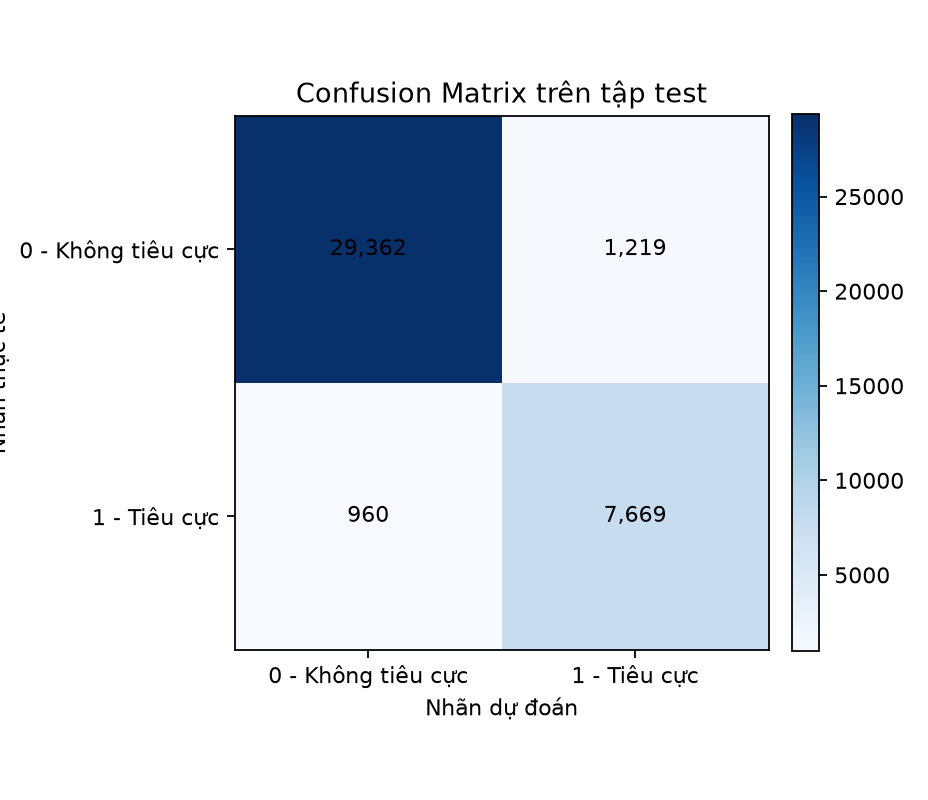

Precision-Recall Curve


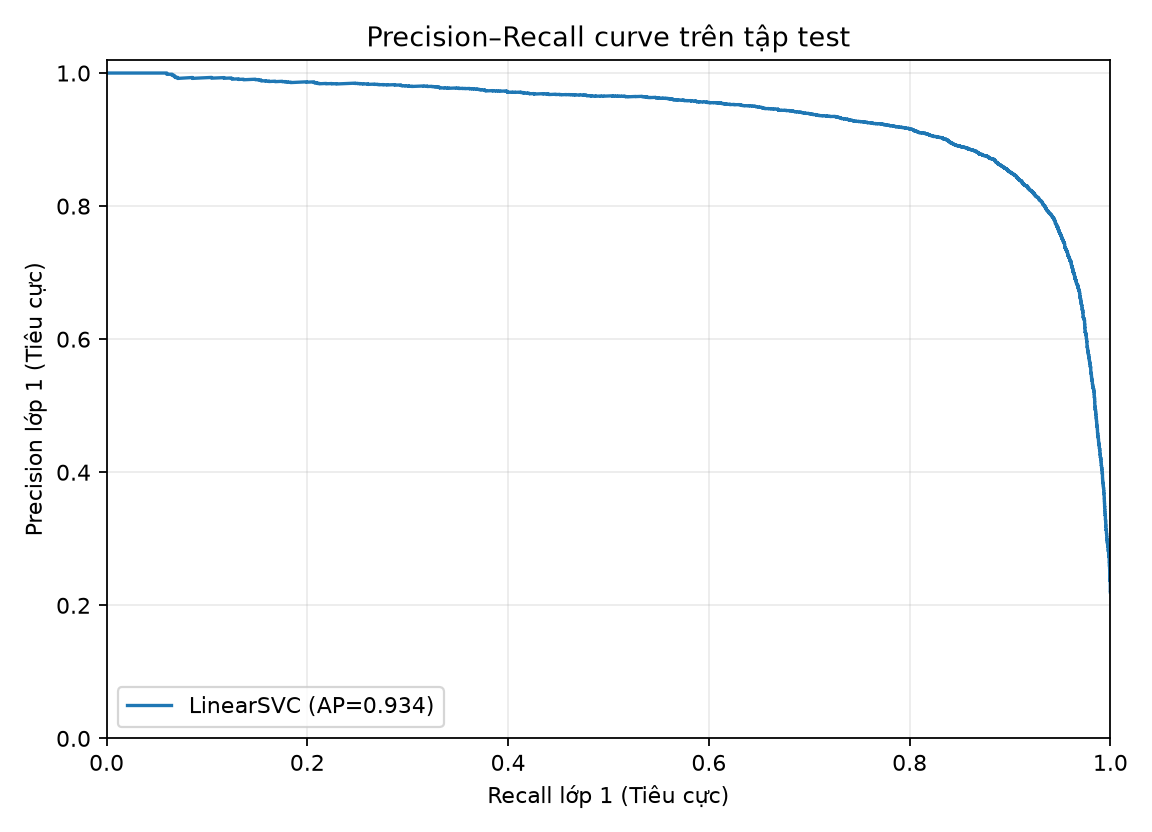

In [39]:
# Hiển thị các bảng đánh giá tổng hợp và biểu đồ ngay dưới cell.
print('1. KẾT QUẢ ĐÁNH GIÁ TEST CHÍNH (LINEARSVC):')
display(pd.DataFrame([metrics['decision']['test_threshold_selected']]).T.rename(columns={0: 'Giá trị'}))

print('2. KẾT QUẢ THEO TỪNG NGUỒN (TWITTER vs REDDIT):')
display(pd.DataFrame(metrics['by_source']).T)

print('3. KIỂM TRA CHÉO MIỀN (CROSS-DOMAIN):')
display(pd.DataFrame(metrics['cross_domain']))

print('4. MỞ RỘNG 3 LỚP (-1 / 0 / 1) CHỨNG MINH GỘP NHÃN:')
display(pd.DataFrame(metrics['three_class_extension']['per_class']).T)

if 'real_world_eval' in metrics:
    print('5. ĐÁNH GIÁ TẬP TWEET THỰC TẾ ĐỘC LẬP (2 NGƯỜI GÁN NHÃN):')
    rw = {k: v for k, v in metrics['real_world_eval'].items() if k not in ('confusion_matrix_labels_0_1', 'note')}
    display(pd.DataFrame([rw]).T.rename(columns={0: 'Giá trị'}))

print('6. TOP 15 TỪ QUAN TRỌNG NHẤT CỦA LINEARSVC:')
feat_df = pd.read_csv(OUTPUT / 'binary_feature_importance.csv')
display(feat_df.groupby('direction').head(15))

print('7. 20 MẪU PHÂN TÍCH LỖI:')
display(pd.read_csv(OUTPUT / 'binary_error_20_samples.csv')[['source', 'error_type', 'error_group', 'true_label', 'predicted_label', 'text']])

for title, name in [('Confusion Matrix', 'binary_confusion_matrix.png'),
                    ('Precision-Recall Curve', 'binary_pr_curve.png')]:
    print(title)
    display(Image(filename=str(OUTPUT / name)))

**3.6. Lưu mô hình và các file kết quả thực nghiệm**

In [40]:
# Huấn luyện lại mô hình cuối trên Train + Validation với (best_c, threshold) đã chọn, rồi lưu .joblib và manifest.
train_val_df = pd.concat([train_df, val_df], ignore_index=True)
final_pipeline = make_pipeline(max_features, min_df, LinearSVC(C=best_c, max_iter=max_iter, random_state=SEED))
final_pipeline.fit(train_val_df['text'], train_val_df[ycol])
metrics['final_production_model'] = {
    'trained_on': 'train+validation',
    'rows': int(len(train_val_df)),
    'selected_C': float(best_c),
    'threshold': float(threshold),
    'note': 'Mọi đánh giá Test ở trên được đo trên mô hình fit bằng Train; artifact .joblib cuối cùng được fit lại trên Train+Validation với cùng siêu tham số đã chọn.'
}

artifact = {
    'pipeline': final_pipeline, 'task': 'binary', 'class_names': mapping,
    'threshold': float(threshold), 'sklearn_version': sklearn.__version__,
    'created_utc': metrics['created_utc'], 'python_version': platform.python_version(),
    'data_sha256': stats.get('canonical_dataset_sha256'), 'selected_C': float(best_c),
    'preprocessing_version': PREPROCESSING_VERSION,
    'trained_on': 'train+validation',
}
out.mkdir(parents=True, exist_ok=True)
model_path = out / 'binary_linear_svm.joblib'
joblib.dump(artifact, model_path, compress=3)
metrics_path = out / 'binary_metrics.json'
metrics_path.write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')

result = test_df[[c for c in ('source', 'text', 'category') if c in test_df]].copy()
result['truth'] = test_df[ycol].to_numpy()
result['truth_name'] = [mapping[int(v)] for v in result['truth']]
result['prediction'] = predictions
result['prediction_name'] = [mapping[int(v)] for v in predictions]
result['prediction_threshold_0'] = baseline_threshold_predictions
result['decision_score'] = test_scores
result.to_csv(out / 'binary_test_predictions.csv', index=False, encoding='utf-8-sig')

manifest = {
    'task': 'binary', 'created_utc': metrics['created_utc'], 'seed': SEED,
    'data_hashes': metrics['data_hashes'], 'split_file_sha256': split_hashes,
    'split_rows': {'train': len(train_df), 'validation': len(val_df), 'test': len(test_df)},
    'model_file_sha256': sha256_file(model_path), 'metrics_file_sha256': sha256_file(metrics_path)
}
(out / 'binary_manifest.json').write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')

980

**3.7. Ghi lịch sử huấn luyện vào SQL Server**

SQL Server là nơi lưu lịch sử huấn luyện của TextSense. Cell này sử dụng cùng chuỗi kết nối đã kiểm tra ở bước 1.4. Nếu không kết nối được hoặc thiếu bảng, cell sẽ báo lỗi rõ ràng thay vì âm thầm bỏ qua.


In [41]:
if os.environ.get('TEXTSENSE_SKIP_SQL') == '1':
    print('TEXTSENSE_SKIP_SQL=1: Bỏ qua bước ghi TrainingRuns vào SQL Server.')
else:
    # Ghi lần huấn luyện hoàn tất vào dbo.TrainingRuns.
    import pyodbc
    
    if not SQLSERVER_CONNECTION_STRING:
        raise RuntimeError('Chưa có chuỗi kết nối SQL Server. Hãy chạy cell 1.4 trước.')
    
    manifest_path = out / 'binary_manifest.json'
    manifest_sha256 = sha256_file(manifest_path)
    positive_report = metrics.get('classification_report', {}).get('Tiêu cực', {})
    
    with pyodbc.connect(SQLSERVER_CONNECTION_STRING, timeout=15) as sql_conn:
        cursor = sql_conn.cursor()
        cursor.execute('''
            INSERT INTO dbo.TrainingRuns
            (StartedUtc, Task, Status, ModelPath, Accuracy, MacroF1, PrecisionPositive,
             RecallPositive, F1Positive, TestRows, SelectedC, DecisionThreshold,
             PythonVersion, SklearnVersion, DataSha256, ManifestSha256, MetricsJson, LogText)
            OUTPUT INSERTED.TrainingRunID
            VALUES (SYSDATETIMEOFFSET(), ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
        ''', (
            'binary', 'completed', str(model_path.resolve()),
            metrics.get('accuracy'), metrics.get('f1_macro'), positive_report.get('precision'),
            positive_report.get('recall'), positive_report.get('f1-score'), metrics.get('test_rows'),
            metrics.get('tuning', {}).get('selected_C'),
            metrics.get('decision', {}).get('validation_selected_threshold'),
            metrics.get('python_version'), metrics.get('sklearn_version'),
            metrics.get('data_hashes', {}).get('canonical_dataset_sha256'),
            manifest_sha256, json.dumps(metrics, ensure_ascii=False, default=str),
            'Huấn luyện hoàn tất từ TextSense_Notebook_V3_13.ipynb'
        ))
        training_run_id = int(cursor.fetchone()[0])
        sql_conn.commit()
    
    print(f'Đã lưu lịch sử huấn luyện vào SQL Server. TrainingRunID={training_run_id}')

Đã lưu lịch sử huấn luyện vào SQL Server. TrainingRunID=7


In [42]:
# Liệt kê minh chứng được tạo (không tự sinh báo cáo Markdown).
print('Model:',model_path)
for name in ['binary_metrics.json','binary_model_comparison.csv','binary_cv_results.csv', 'binary_test_predictions.csv','binary_confusion_matrix.png','binary_pr_curve.png','binary_class_weight_experiment.csv']:
    print(('OK' if (OUTPUT/name).is_file() else 'THIẾU'), name)

Model: C:\Users\vothi\OneDrive\Desktop\TextSense\01_TRAIN_MODEL\outputs\binary_linear_svm.joblib
OK binary_metrics.json
OK binary_model_comparison.csv
OK binary_cv_results.csv
OK binary_test_predictions.csv
OK binary_confusion_matrix.png
OK binary_pr_curve.png
OK binary_class_weight_experiment.csv


**3.8. Dự đoán thử một vài câu mới**

In [43]:
# Nạp file .joblib và dự đoán hai câu tiếng Anh để trình diễn.
import joblib
model_file = OUTPUT / 'binary_linear_svm.joblib'
if model_file.exists():
    artifact = joblib.load(model_file)
    examples = ['I love this wonderful day', 'I absolutely hate this terrible experience']
    cleaned_examples = [normalize_text(t) for t in examples]
    scores = artifact['pipeline'].decision_function(cleaned_examples)
    predictions = (scores > artifact['threshold']).astype(int)
    display(pd.DataFrame({'text':examples,'label':predictions,
                          'name':[BINARY_NAMES[int(v)] for v in predictions], 'score':scores}))
else:
    print('Chưa có model; cần chạy cell huấn luyện trước.')

,text,label,name,score
0,I love this wonderful day,0,Không tiêu cực,-5.308514
1,I absolutely hate this terrible experience,1,Tiêu cực,5.889602


## CÂU 4 — THIẾT KẾ ỨNG DỤNG VÀ TRÌNH BÀY (2,0 ĐIỂM)

Giao diện nằm trong thư mục `03_GIAO_DIEN`. Notebook chỉ kiểm tra model và kết quả để ứng dụng sử dụng; không trộn code giao diện vào phần huấn luyện.

**4.1. Kiểm tra file mô hình và các hình minh chứng**

In [44]:
# Kiểm tra model và minh chứng thực nghiệm phục vụ giao diện/bảo vệ.
required_files = [
    'binary_linear_svm.joblib', 'binary_metrics.json',
    'binary_model_comparison.csv', 'binary_cv_results.csv',
    'binary_confusion_matrix.png', 'binary_pr_curve.png', 'binary_class_weight_experiment.csv',
]
for name in required_files:
    file_path = OUTPUT / name
    print(('OK' if file_path.is_file() else 'THIẾU'), name)


OK binary_linear_svm.joblib
OK binary_metrics.json
OK binary_model_comparison.csv
OK binary_cv_results.csv
OK binary_confusion_matrix.png
OK binary_pr_curve.png
OK binary_class_weight_experiment.csv


**4.2. Chạy giao diện từ Terminal VS Code**

```powershell
py -3 -m pip install -r 03_GIAO_DIEN/requirements.txt
cd 03_GIAO_DIEN
py -3 serve_textsense.py
```

Truy cập `http://127.0.0.1:8502`. Trình diễn dự đoán câu đơn và tải CSV. Đưa ảnh chụp màn hình vào **báo cáo Word riêng**; không cần cell tạo báo cáo Markdown trong Câu 3.